In [30]:
from typing import List, Dict, Any, Tuple, Literal
import os

import pandas as pd

attributes = [
  "experiment_tag",
  "time_to_reach_goal",
  "path_length",
  "cumulative_heading_changes",
  "avg_distance_to_closest_person",
  "minimum_distance_to_people",
  "maximum_distance_to_people",
  "intimate_space_intrusions",
  "personal_space_intrusions",
  "social_space_intrusions",
  "group_intimate_space_intrusions",
  "group_personal_space_intrusions",
  "group_social_space_intrusions",
  "completed",
  "minimum_distance_to_target",
  "final_distance_to_target",
  "robot_on_person_collision",
  "person_on_robot_collision",
  "time_not_moving",
  "avg_robot_linear_speed",
  "avg_robot_angular_speed",
  "avg_acceleration",
  "avg_overacceleration",
  "avg_pedestrian_velocity",
  "avg_closest_pedestrian_velocity",
  "social_force_on_agents",
  "social_force_on_robot",
  "social_work",
  "obstacle_force_on_robot",
  "obstacle_force_on_agents"
  ]

In [31]:
def read_outcome(log_input_file: str) -> pd.Series:
  # get outcome from log file and add it to the dataframe
  with open(log_input_file, 'r') as f:
    lines = f.readlines()
    # if Goal or Collision or Timeout in line
    outcome = [line for line in lines if 'Goal' in line or 'Collision' in line or 'Timeout' in line]
  for i in range(len(outcome)):
    if 'Goal' in outcome[i]:
      outcome[i] = 'Goal'
    elif 'Collision' in outcome[i]:
      outcome[i] = 'Collision'
    elif 'Timeout' in outcome[i]:
      outcome[i] = 'Timeout'
    else:
      outcome[i] = 'Unknown'
  return pd.Series(outcome)

In [32]:
def compare_statistics(statistics: str, statistics_2: str, output_file: str, title: str) -> pd.DataFrame:

  mean_diff = statistics.groupby('episode').mean(numeric_only=True) - statistics_2.groupby('episode').mean(numeric_only=True)
  max_diff = statistics.groupby('episode').max(numeric_only=True) - statistics_2.groupby('episode').max(numeric_only=True)
  min_diff = statistics.groupby('episode').min(numeric_only=True) - statistics_2.groupby('episode').min(numeric_only=True)
  std_diff = statistics.groupby('episode').std(numeric_only=True) - statistics_2.groupby('episode').std(numeric_only=True)

  with pd.ExcelWriter(f"{output_file}.xlsx",engine='openpyxl', mode='a') as writer:
    mean_diff.to_excel(writer, sheet_name=f"mean_diff_{title}", index=True, header=True)
    max_diff.to_excel(writer, sheet_name=f"max_diff_{title}", index=True, header=True)
    min_diff.to_excel(writer, sheet_name=f"min_diff_{title}", index=True, header=True)
    std_diff.to_excel(writer, sheet_name=f"std_diff_{title}", index=True, header=True)
  return mean_diff

In [33]:
def create_stat(full_data: pd.DataFrame, label: str) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
  # MAX
  max = full_data.where(full_data.Outcome.str.contains('Goal')).groupby('episode').max(numeric_only=True)
  max = max.reset_index()
  max_avg = full_data.where(full_data.Outcome.str.contains('Goal')).max(numeric_only=True)
  max_avg['episode'] = 'Average'
  max.loc[len(max)] = max_avg
  # add label
  max['label'] = label
  nan_rows = []
  for i in full_data.groupby('episode').groups.keys():
    if i not in max['episode'].tolist():
      nan_row = pd.DataFrame(columns=max.columns)
      nan_row['episode'] = i
      nan_row['label'] = label
      # max = pd.concat([max, nan_row], ignore_index=True)
      nan_rows.append(nan_row)
  max = pd.concat([max, *nan_rows], ignore_index=True)
  # MEAN
  mean = full_data.where(full_data.Outcome.str.contains('Goal')).groupby('episode').mean(numeric_only=True)
  mean = mean.reset_index()
  mean_avg = full_data.where(full_data.Outcome.str.contains('Goal')).mean(numeric_only=True)
  mean_avg['episode'] = 'Average'
  mean.loc[len(mean)] = mean_avg
  # add label
  mean['label'] = label
  nan_rows = []
  for i in full_data.groupby('episode').groups.keys():
    if i not in mean['episode'].tolist():
      nan_row = pd.DataFrame(columns=mean.columns)
      nan_row['episode'] = i
      nan_row['label'] = label
      # mean = pd.concat([mean, nan_row], ignore_index=True)
      nan_rows.append(nan_row)
  mean = pd.concat([mean, *nan_rows], ignore_index=True)

  # MIN
  min = full_data.where(full_data.Outcome.str.contains('Goal')).groupby('episode').min(numeric_only=True)
  min = min.reset_index()
  min_avg = full_data.where(full_data.Outcome.str.contains('Goal')).min(numeric_only=True)
  min_avg['episode'] = 'Average'
  min.loc[len(min)] = min_avg
  # add label
  min['label'] = label
  nan_rows = []
  for i in full_data.groupby('episode').groups.keys():
    if i not in min['episode'].tolist():
      nan_row = pd.DataFrame(columns=min.columns)
      nan_row['episode'] = i
      nan_row['label'] = label
      # min = pd.concat([min, nan_row], ignore_index=True)
      nan_rows.append(nan_row)
  min = pd.concat([min, *nan_rows], ignore_index=True)
      


  # STD
  std = full_data.where(full_data.Outcome.str.contains('Goal')).groupby('episode').std(numeric_only=True)
  std = std.reset_index()
  std_avg = full_data.where(full_data.Outcome.str.contains('Goal')).std(numeric_only=True)
  std_avg['episode'] = 'Average'
  std.loc[len(std)] = std_avg
  # add label
  std['label'] = label
  nan_rows = []
  for i in full_data.groupby('episode').groups.keys():
    if i not in std['episode'].tolist():
      nan_row = pd.DataFrame(columns=std.columns)
      nan_row['episode'] = i
      nan_row['label'] = label
      nan_rows.append(nan_row)
  std = pd.concat([std, *nan_rows], ignore_index=True)
  return max, mean, min, std

In [34]:
from matplotlib import pyplot as plt
def create_plot(ax: plt.Axes, mean: pd.DataFrame, std: pd.DataFrame, label: str):
  metric_mean = mean.pivot(index='episode', values=label, columns='label')
  metric_err = std.pivot(index='episode', values=label, columns='label')
  metric_mean.plot.bar(ax=ax, yerr=metric_err, label=label, rot=0,capsize=4)


## Retrieve Files And create stats

### Parse the data from the files to create a dataframe 

In [35]:
def parse_txt_to_df(input_file : str, attributes: List[str], n_episodes: int, outcomes: pd.Series = None) -> List[pd.DataFrame]:
    # Read the text file into a DataFrame
    df = pd.read_csv(input_file, sep='\t' )
    parsed_df = df[attributes]
    parsed_df.insert(loc=0,column='Outcome',value=outcomes)
    dataframes = []
    for i in range(len(parsed_df) // n_episodes):
        # filter dataframe for each episode
        ep_df = parsed_df.iloc[i*n_episodes:(i+1)*n_episodes]
        ep_df.insert(loc=0, column='episode', value=[int(i+1) for i in range(n_episodes)])
        if outcomes is None:
          ep_df.insert(loc=1, column='Outcome', value='Goal')
        dataframes.append(ep_df)

    attributes = ['episode', 'Outcome'] + attributes

    full_data = pd.concat(dataframes)
    # full_data.sort_values(by=['episode'], inplace=True)
    # full_data.reset_index(drop=True, inplace=True)

    return full_data

def parse_n_steps(input_dir: str, n_tot_runs: int) -> List[int]:
  n_steps = []
  for i in range(n_tot_runs):
    # /home/user/applr_ws/src/Results/test/DumbNav/SFW_base/social_nav/20240309_224247.602813_applr_SAC/evaluator/metrics_steps_1.txt
    with open(f"{input_dir}/metrics_steps_{i+1}.txt", 'r') as f:
      lines = f.readlines()
      n_steps.append(len(lines)+1)
  return n_steps

### Classes to handle the files and create stats

In [36]:
# FILES
import os
from pathlib import Path

class ExpData():
  def __init__(self, base_path: Path) -> None:
    self.input_file = os.path.join(base_path, 'evaluator', 'metrics.txt')
    self.log_input_file = os.path.join(base_path, 'screen_logger.log')
    self.df = None
    self.stat = None

  def __str__(self) -> str:
    return f"\nInput file: {self.input_file}\nLog input file: {self.log_input_file}"
  
  def parse_df(self, attributes: List[str], n_episodes: int) -> pd.DataFrame:
    self.df = parse_txt_to_df(self.input_file, attributes, n_episodes, read_outcome(self.log_input_file))
    n_tot_runs = len(self.df)
    self.df.insert(loc=1, column='n_steps', value=parse_n_steps(os.path.dirname(self.input_file), n_tot_runs))
    
  def create_stat(self, label):
    self.stat = create_stat(self.df, label)
    self.stat_concat = pd.concat([*self.stat], keys=['max', 'mean', 'min', 'std'], axis=0)

  def create_summary(self, label: 'str'):
    # create summary table
    self.summary = self.df.pivot_table(index='episode', columns='Outcome', aggfunc='size', fill_value=0)
    if 'Goal' not in self.summary.columns:
      self.summary['Goal'] = 0
    if 'Collision' not in self.summary.columns:
      self.summary['Collision'] = 0
    if 'Timeout' not in self.summary.columns:
      self.summary['Timeout'] = 0
    self.summary.reset_index(inplace=True)
    self.summary['label'] = label
    table = self.summary.pivot_table(index='label', values=['Goal', 'Collision', 'Timeout'], aggfunc='mean')
    table.reset_index(inplace=True)
    table['episode'] = 'average'
    self.summary = pd.concat([self.summary, table])

  def get_episode(self, episode: int) -> pd.DataFrame:
    return self.df[self.df['episode'] == episode]
  
  def get_run_from_episode(self, episode: int, run: int) -> pd.DataFrame:
    return self.df[self.df['episode'] == episode].iloc[[run]]

  @property
  def get_df(self):
    return self.df
  
  @property
  def get_stat(self):
    return self.stat
  
  @property
  def get_stat_concat(self):
    return self.stat_concat
  
  @property
  def get_max(self):
    return self.stat[0]
  
  @property
  def get_mean(self):
    return self.stat[1]
  
  @property
  def get_min(self):
    return self.stat[2]
  
  @property
  def get_std(self):
    return self.stat[3]
  
  @property
  def get_summary(self):
    return self.summary


In [37]:
class Experiments():
  def __init__(self, base_path: str) -> None:
    self.name = base_path.split('/')[-1] 
    base_path = Path(base_path)
    social_nav = os.path.join(base_path, 'social_nav', os.listdir(os.path.join(base_path, 'social_nav'))[-1])
    crossing = os.path.join(base_path, 'crossing', os.listdir(os.path.join(base_path, 'crossing'))[-1])
    passing = os.path.join(base_path, 'passing', os.listdir(os.path.join(base_path, 'passing'))[-1])
    overtaking = os.path.join(base_path, 'overtaking', os.listdir(os.path.join(base_path, 'overtaking'))[-1])
    social_env = os.path.join(base_path, 'social_env', os.listdir(os.path.join(base_path, 'social_env'))[-1])
    social_env7 = os.path.join(base_path, 'social_env7', os.listdir(os.path.join(base_path, 'social_env7'))[-1])
    self.social_nav = ExpData(social_nav)
    # self.crossing = ExpData(crossing)
    # self.overtaking = ExpData(overtaking)
    # self.passing = ExpData(passing)
    self.social_env = ExpData(social_env)
    self.social_env7 = ExpData(social_env7)
  def __str__(self) -> str:
    return f"\nExperiment:{self.name} \nSocial Navigation: {self.social_nav}\nCrossing: {self.crossing}\nOvertaking: {self.overtaking} \nPassing: {self.passing} \nSocial Environment: {self.social_env} \nSocial Environment 7: {self.social_env7}"

  def create_stats(self, label : str = None):
    if label is None:
      label = self.name
    self.social_nav.create_stat(label)
    # self.crossing.create_stat(label)
    # self.passing.create_stat(label)
    # self.overtaking.create_stat(label)
    self.social_env.create_stat(label)
    self.social_env7.create_stat(label)

  def create_summary(self, label: str = None):
    if label is None:
      label = self.name
    self.social_nav.create_summary(label)
    # self.crossing.create_summary(label)
    # self.passing.create_summary(label)
    # self.overtaking.create_summary(label)
    self.social_env.create_summary(label)
    self.social_env7.create_summary(label)
  
  def parse_df(self, attributes: List[str], n_episodes: Dict[str, int]):
    self.social_nav.parse_df(attributes, n_episodes['social_nav'])
    # self.crossing.parse_df(attributes, n_episodes['crossing'])
    # self.passing.parse_df(attributes, n_episodes['passing'])
    # self.overtaking.parse_df(attributes, n_episodes['overtaking'])
    self.social_env.parse_df(attributes, n_episodes['social_env'])
    self.social_env7.parse_df(attributes, n_episodes['social_env7'])
    
  def get_df(self):
    return self.social_nav.df, self.crossing.df, self.passing.df,  self.overtaking.df, self.social_env.df, self.social_env7.df
  
  def get_stats(self):
    return self.social_nav.stat, self.crossing.stat, self.passing.stat , self.overtaking.stat, self.social_env.stat, self.social_env7.stat
  
  def write_to_excel(self, output_file: str):
    
    with pd.ExcelWriter(f"{output_file}.xlsx",engine= 'openpyxl', mode='w') as writer:
      self.social_nav.df.to_excel(writer, sheet_name=f"social_nav", index=False, header=True)
      self.social_nav.stat_concat.to_excel(writer, sheet_name=f"social_nav_stat", index=False, header=True)
      self.social_nav.summary.to_excel(writer, sheet_name=f"social_nav_summary", index=False, header=True)
      # self.crossing.df.to_excel(writer, sheet_name=f"crossing", index=False, header=True)
      # self.crossing.stat_concat.to_excel(writer, sheet_name=f"crossing_stat", index=False, header=True)
      # self.crossing.summary.to_excel(writer, sheet_name=f"crossing_summary", index=False, header=True)
      # self.passing.df.to_excel(writer, sheet_name=f"passing", index=False, header=True)
      # self.passing.stat_concat.to_excel(writer, sheet_name=f"passing_stat", index=False, header=True)
      # self.passing.summary.to_excel(writer, sheet_name=f"passing_summary", index=False, header=True)
      # self.overtaking.df.to_excel(writer, sheet_name=f"overtaking", index=False, header=True)
      # self.overtaking.stat_concat.to_excel(writer, sheet_name=f"overtaking_stat", index=False, header=True)
      # self.overtaking.summary.to_excel(writer, sheet_name=f"overtaking_summary", index=False, header=True)
      self.social_env.df.to_excel(writer, sheet_name=f"social_env", index=False, header=True)
      self.social_env.stat_concat.to_excel(writer, sheet_name=f"social_env_stat", index=False, header=True)
      self.social_env.summary.to_excel(writer, sheet_name=f"social_env_summary", index=False, header=True)
      self.social_env7.df.to_excel(writer, sheet_name=f"social_env7", index=False, header=True)
      self.social_env7.stat_concat.to_excel(writer, sheet_name=f"social_env7_stat", index=False, header=True)
    
  def get_episode(self, episode: int):
    social_nav = self.social_nav.get_episode(episode)
    # crossing = self.crossing.get_episode(episode)
    # passing = self.passing.get_episode(episode)
    # overtaking = self.overtaking.get_episode(episode)
    social_env = self.social_env.get_episode(episode)
    social_env7 = self.social_env7.get_episode(episode)
    # return social_nav, crossing, passing, overtaking, social_env
    return social_nav, social_env, social_env7
  


### Retrieve the files from the input folder and create stats

In [38]:
## BASELINES
experiments_SFW = Experiments("/home/user/applr_ws/src/Results/test/DumbNav/SFW")
experiments_SFW_base = Experiments("/home/user/applr_ws/src/Results/test/DumbNav/SFW_base")
## RL
# experiments_SAC_NR_2 = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SAC_NR_2")
# experiments_SAC_NR_2_2f = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SAC_NR_2_2.0f")
# experiments_SAC_NR_3 = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SAC_NR_3")
# experiments_SAC_NR_3_2f = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SAC_NR_3_2.0f")
# experiments_SAC_NR_4 = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SAC_NR_4")
experiments_SAC_160k = Experiments("/home/user/applr_ws/src/Results/test/SFW/SAC/SFW_SAC_160k")

attributes_ind = [i for i in range(1,6)] + [i for i in range(7,10)] + [i for i in range(16,21)] + [i for i in range(25,29)] 
attributes_names = [attributes[i] for i in attributes_ind]

n_episodes = {
  'social_nav': 10,
  'social_env': 10,
  'crossing': 2,
  'passing': 1,
  'overtaking': 3,
  'social_env7': 2
}

# experiments = [experiments_SFW, experiments_SFW_base, experiments_SAC_NR_2, experiments_SAC_NR_2_2f, experiments_SAC_NR_3, experiments_SAC_NR_3_2f]
experiments = [experiments_SFW, experiments_SFW_base, experiments_SAC_160k]
for experiment in experiments:
  experiment.parse_df(attributes_names, n_episodes)
  experiment.create_stats()
  experiment.create_summary()

/tmp/ipykernel_2527853/976464393.py:6: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Average' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  max_avg['episode'] = 'Average'
/tmp/ipykernel_2527853/976464393.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  max = pd.concat([max, *nan_rows], ignore_index=True)
/tmp/ipykernel_2527853/976464393.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Average' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  mean_avg['episode'] = 'Average'
/tmp/ipyker

### Aggregate the data and create single stats files

In [39]:
# Social Nav
# experiments = [experiments_TD3, experiments_SFW, experiments_SFW_base, experiments_SAC, experiments_SAC_Obstacles]
# experiments = [experiments_SFW, experiments_SFW_base, experiments_SAC_NR_2, experiments_SAC_NR_2_2f, experiments_SAC_NR_3, experiments_SAC_NR_3_2f]
experiments = [experiments_SFW, experiments_SFW_base, experiments_SAC_160k]
max_social_nav_combined = pd.concat([exp.social_nav.get_max for exp in experiments])
mean_social_nav_combined = pd.concat([exp.social_nav.get_mean for exp in experiments])
min_social_nav_combined = pd.concat([exp.social_nav.get_min for exp in experiments])
std_social_nav_combined = pd.concat([exp.social_nav.get_std for exp in experiments])



# Crossing
# max_crossing_combined = pd.concat([exp.crossing.get_max for exp in experiments])
# mean_crossing_combined = pd.concat([exp.crossing.get_mean for exp in experiments])
# min_crossing_combined = pd.concat([exp.crossing.get_min for exp in experiments])
# std_crossing_combined = pd.concat([exp.crossing.get_std for exp in experiments])


# Passing
# max_passing_combined = pd.concat([exp.passing.get_max for exp in experiments])
# mean_passing_combined = pd.concat([exp.passing.get_mean for exp in experiments])
# min_passing_combined = pd.concat([exp.passing.get_min for exp in experiments])
# std_passing_combined = pd.concat([exp.passing.get_std for exp in experiments])


# Overtaking
# max_overtaking_combined = pd.concat([exp.overtaking.get_max for exp in experiments])
# mean_overtaking_combined = pd.concat([exp.overtaking.get_mean for exp in experiments])
# min_overtaking_combined = pd.concat([exp.overtaking.get_min for exp in experiments])
# std_overtaking_combined = pd.concat([exp.overtaking.get_std for exp in experiments])

# Social Env
max_social_env_combined = pd.concat([exp.social_env.get_max for exp in experiments])
mean_social_env_combined = pd.concat([exp.social_env.get_mean for exp in experiments])
min_social_env_combined = pd.concat([exp.social_env.get_min for exp in experiments])
std_social_env_combined = pd.concat([exp.social_env.get_std for exp in experiments])

# Social Env 7
max_social_env7_combined = pd.concat([exp.social_env7.get_max for exp in experiments])
mean_social_env7_combined = pd.concat([exp.social_env7.get_mean for exp in experiments])
min_social_env7_combined = pd.concat([exp.social_env7.get_min for exp in experiments])
std_social_env7_combined = pd.concat([exp.social_env7.get_std for exp in experiments])




### Create excel files with the stats

In [40]:
output_file_SFW_base = "data/SFW_base"
output_file_SFW = "data/SFW"
# output_file_SAC_NR_2 = "data/SAC_NR_2"
# output_file_SAC_NR_2_2f = "data/SAC_NR_2_2f"
# output_file_SAC_NR_3 = "data/SAC_NR_3"
# output_file_SAC_NR_3_2f = "data/SAC_NR_3_2f"
# output_file_SAC_NR_4 = "data/SAC_NR_4"
output_file_SAC_160k = "data/SAC_160k"

experiments_SFW_base.write_to_excel(output_file_SFW_base)
experiments_SFW.write_to_excel(output_file_SFW)
# experiments_SAC_NR_2.write_to_excel(output_file_SAC_NR_2)
# experiments_SAC_NR_2_2f.write_to_excel(output_file_SAC_NR_2_2f)
# experiments_SAC_NR_3.write_to_excel(output_file_SAC_NR_3)
# experiments_SAC_NR_3_2f.write_to_excel(output_file_SAC_NR_3_2f)
# experiments_SAC_NR_4.write_to_excel(output_file_SAC_NR_4)
experiments_SAC_160k.write_to_excel(output_file_SAC_160k)

# PLOTS

In [41]:
attributes_to_plot = [
  "time_to_reach_goal",
  "path_length",
  "avg_distance_to_closest_person",
  "minimum_distance_to_people",
  "intimate_space_intrusions",
  "personal_space_intrusions",
  "social_space_intrusions",
  "avg_robot_linear_speed",
  "social_work"
  ]

## Social Nav

#### Create a plot with the social navigation data

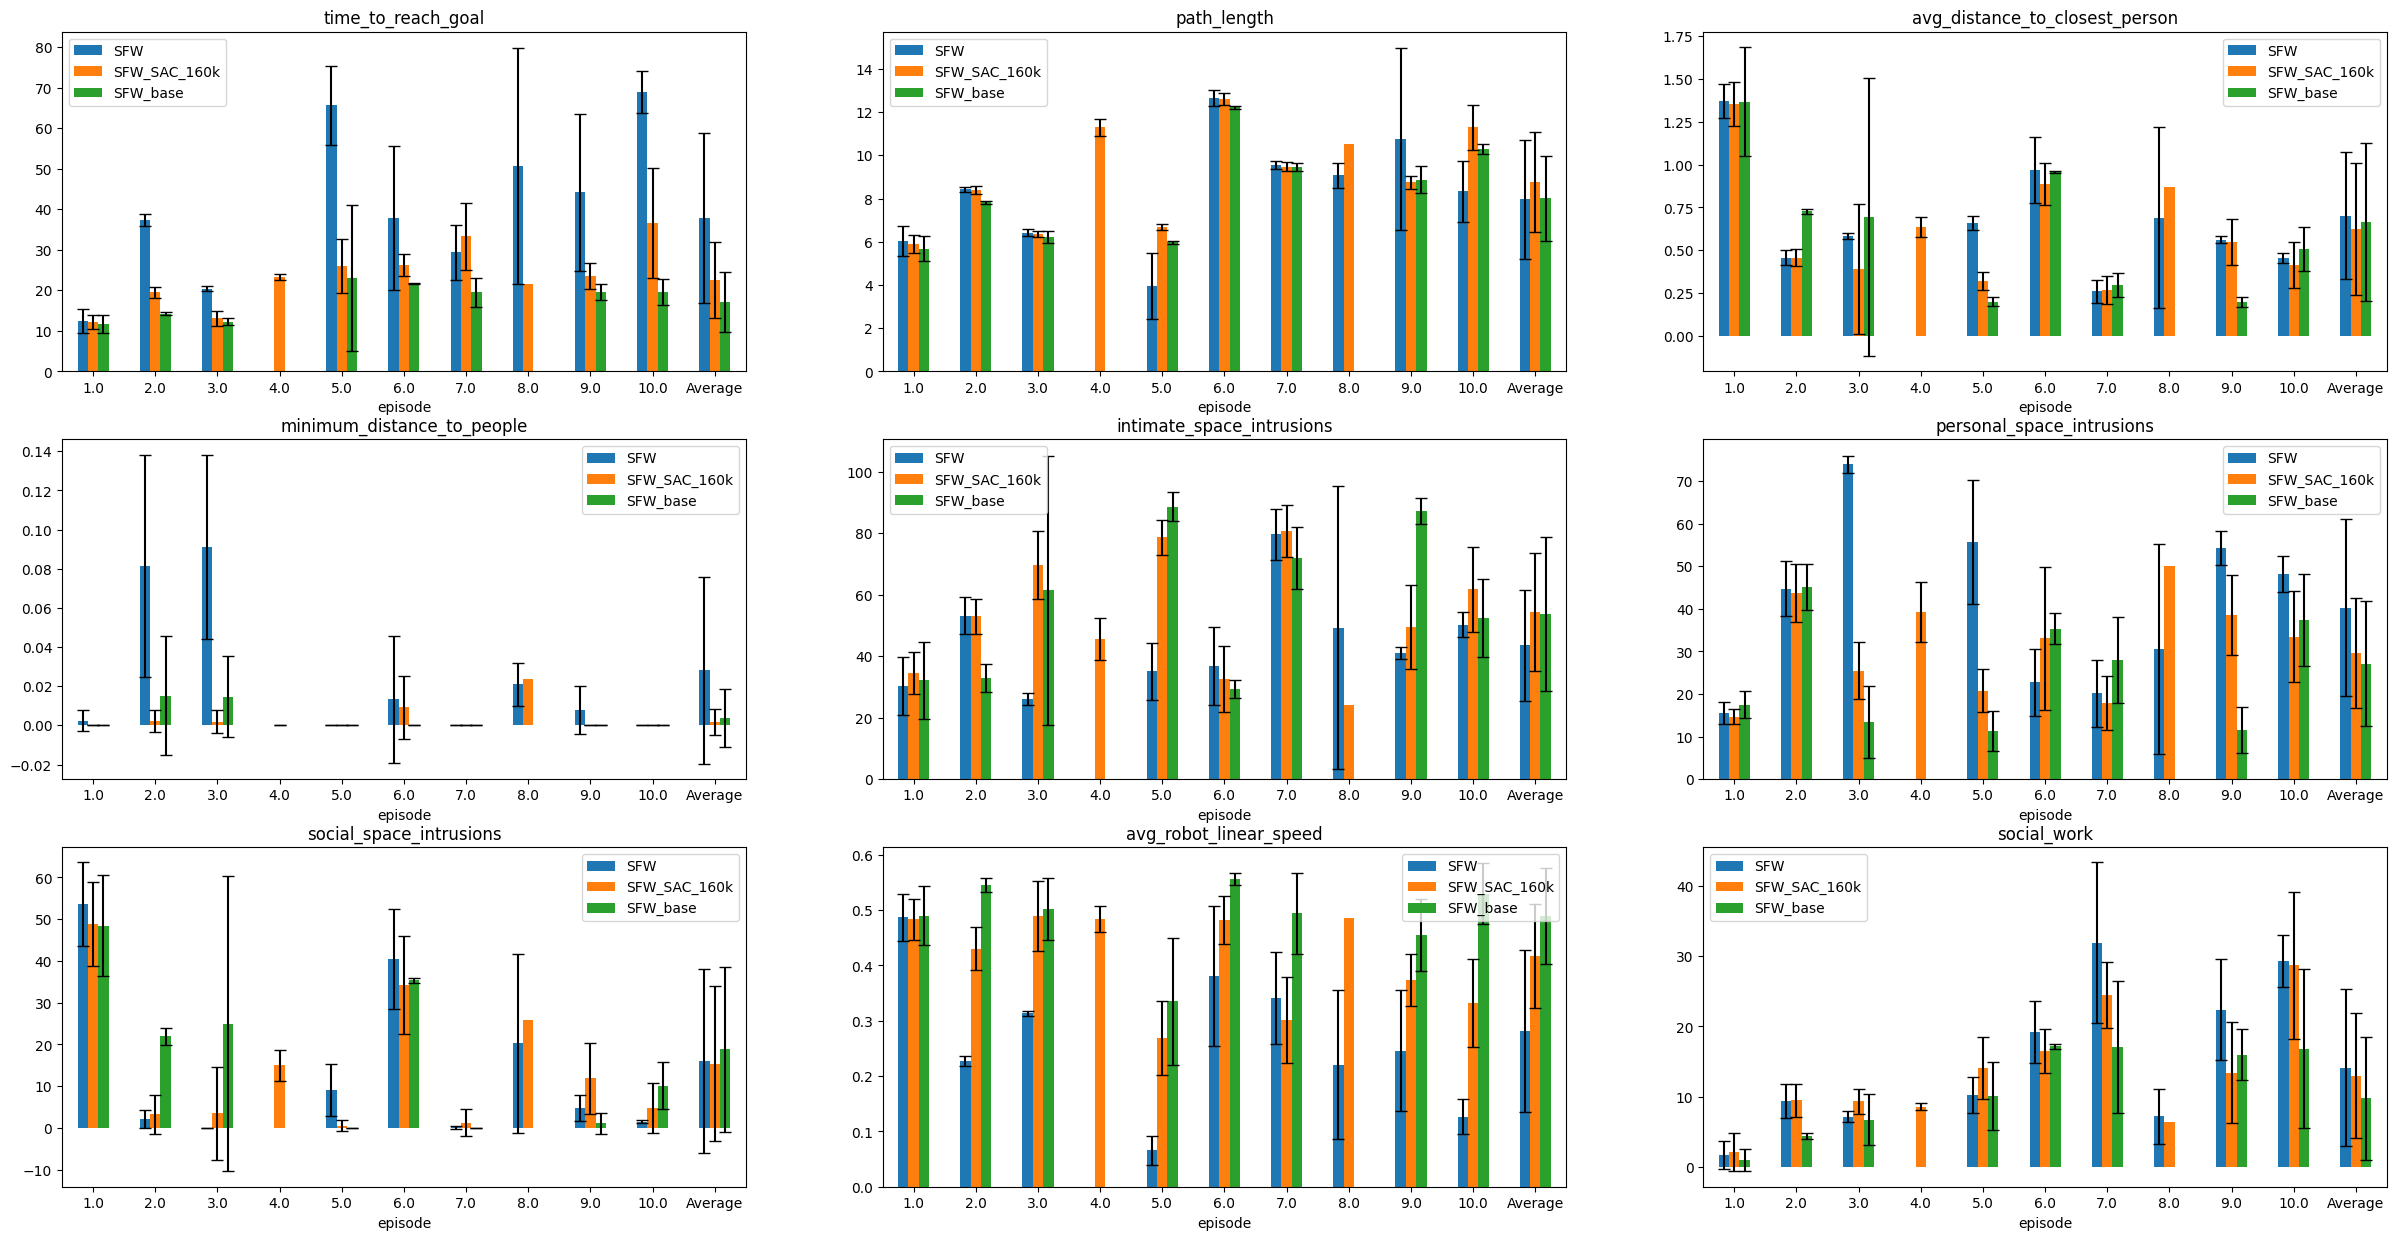

In [42]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_social_nav_combined, std_social_nav_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/social_nav.png")

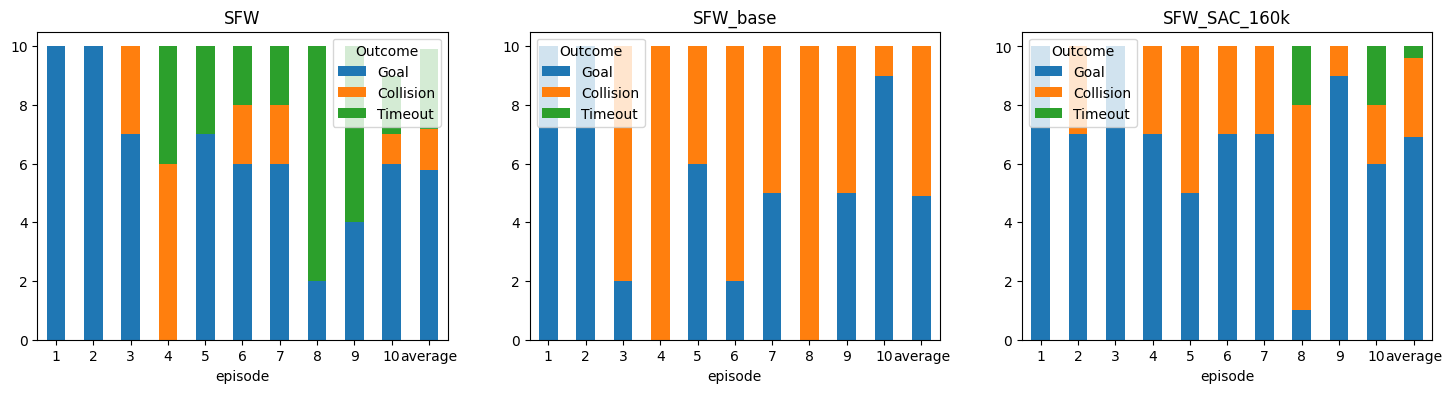

In [43]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_social_nav = pd.concat([exp.social_nav.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.social_nav.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.social_nav.get_summary['label'].iloc[0])

fig.savefig('plot/social_nav_summary.png')


#### Create a table with the social navigation data

## Crossing

NameError: name 'mean_crossing_combined' is not defined

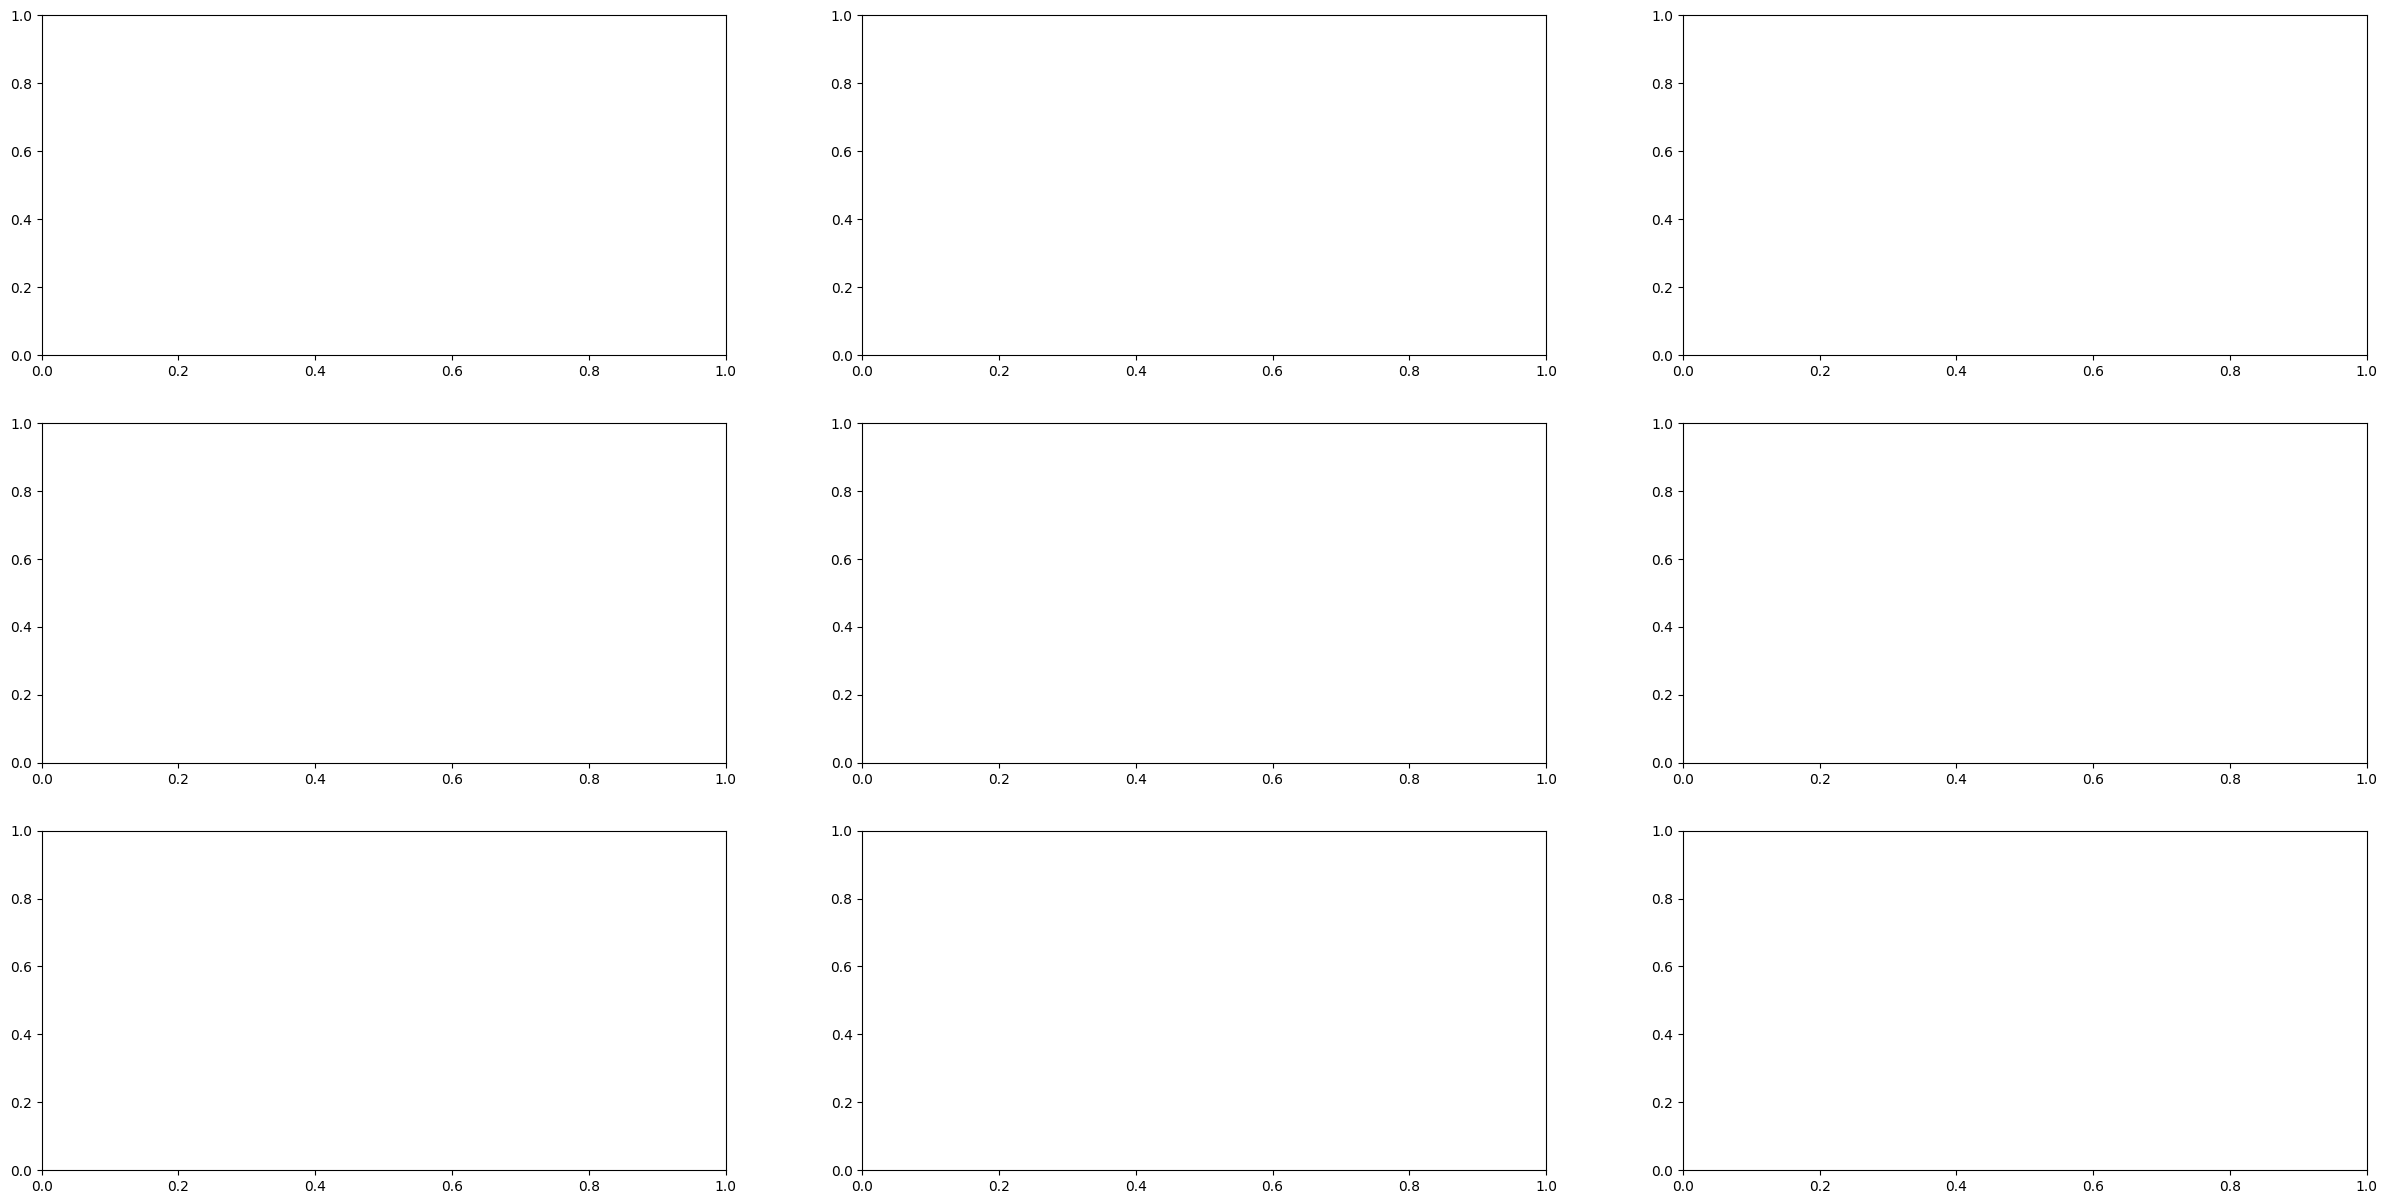

In [44]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_crossing_combined, std_crossing_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/crossing.png")

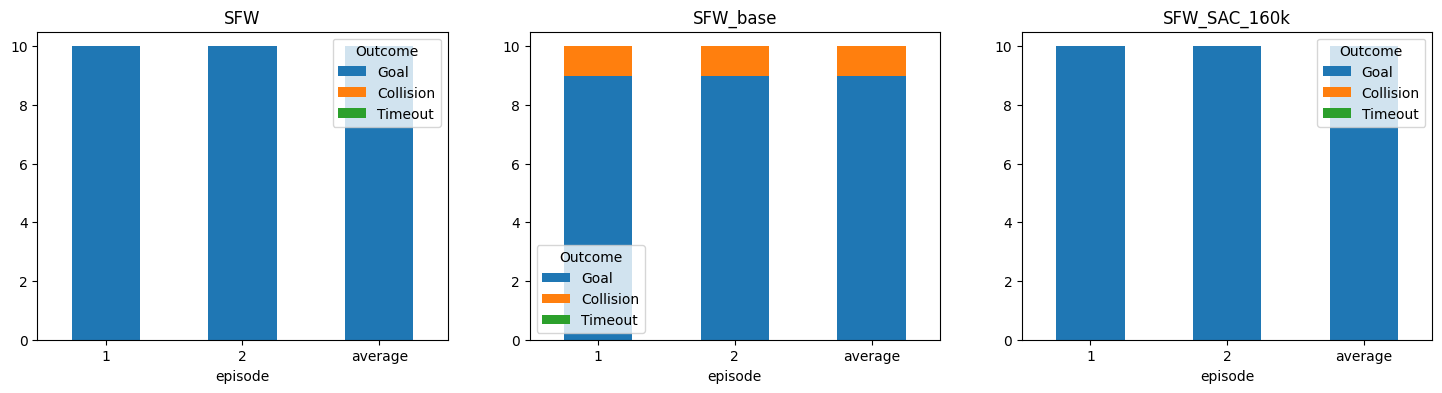

In [ ]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_crossing = pd.concat([exp.crossing.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.crossing.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.crossing.get_summary['label'].iloc[0])

fig.savefig('plot/crossing_summary.png')


## Passing

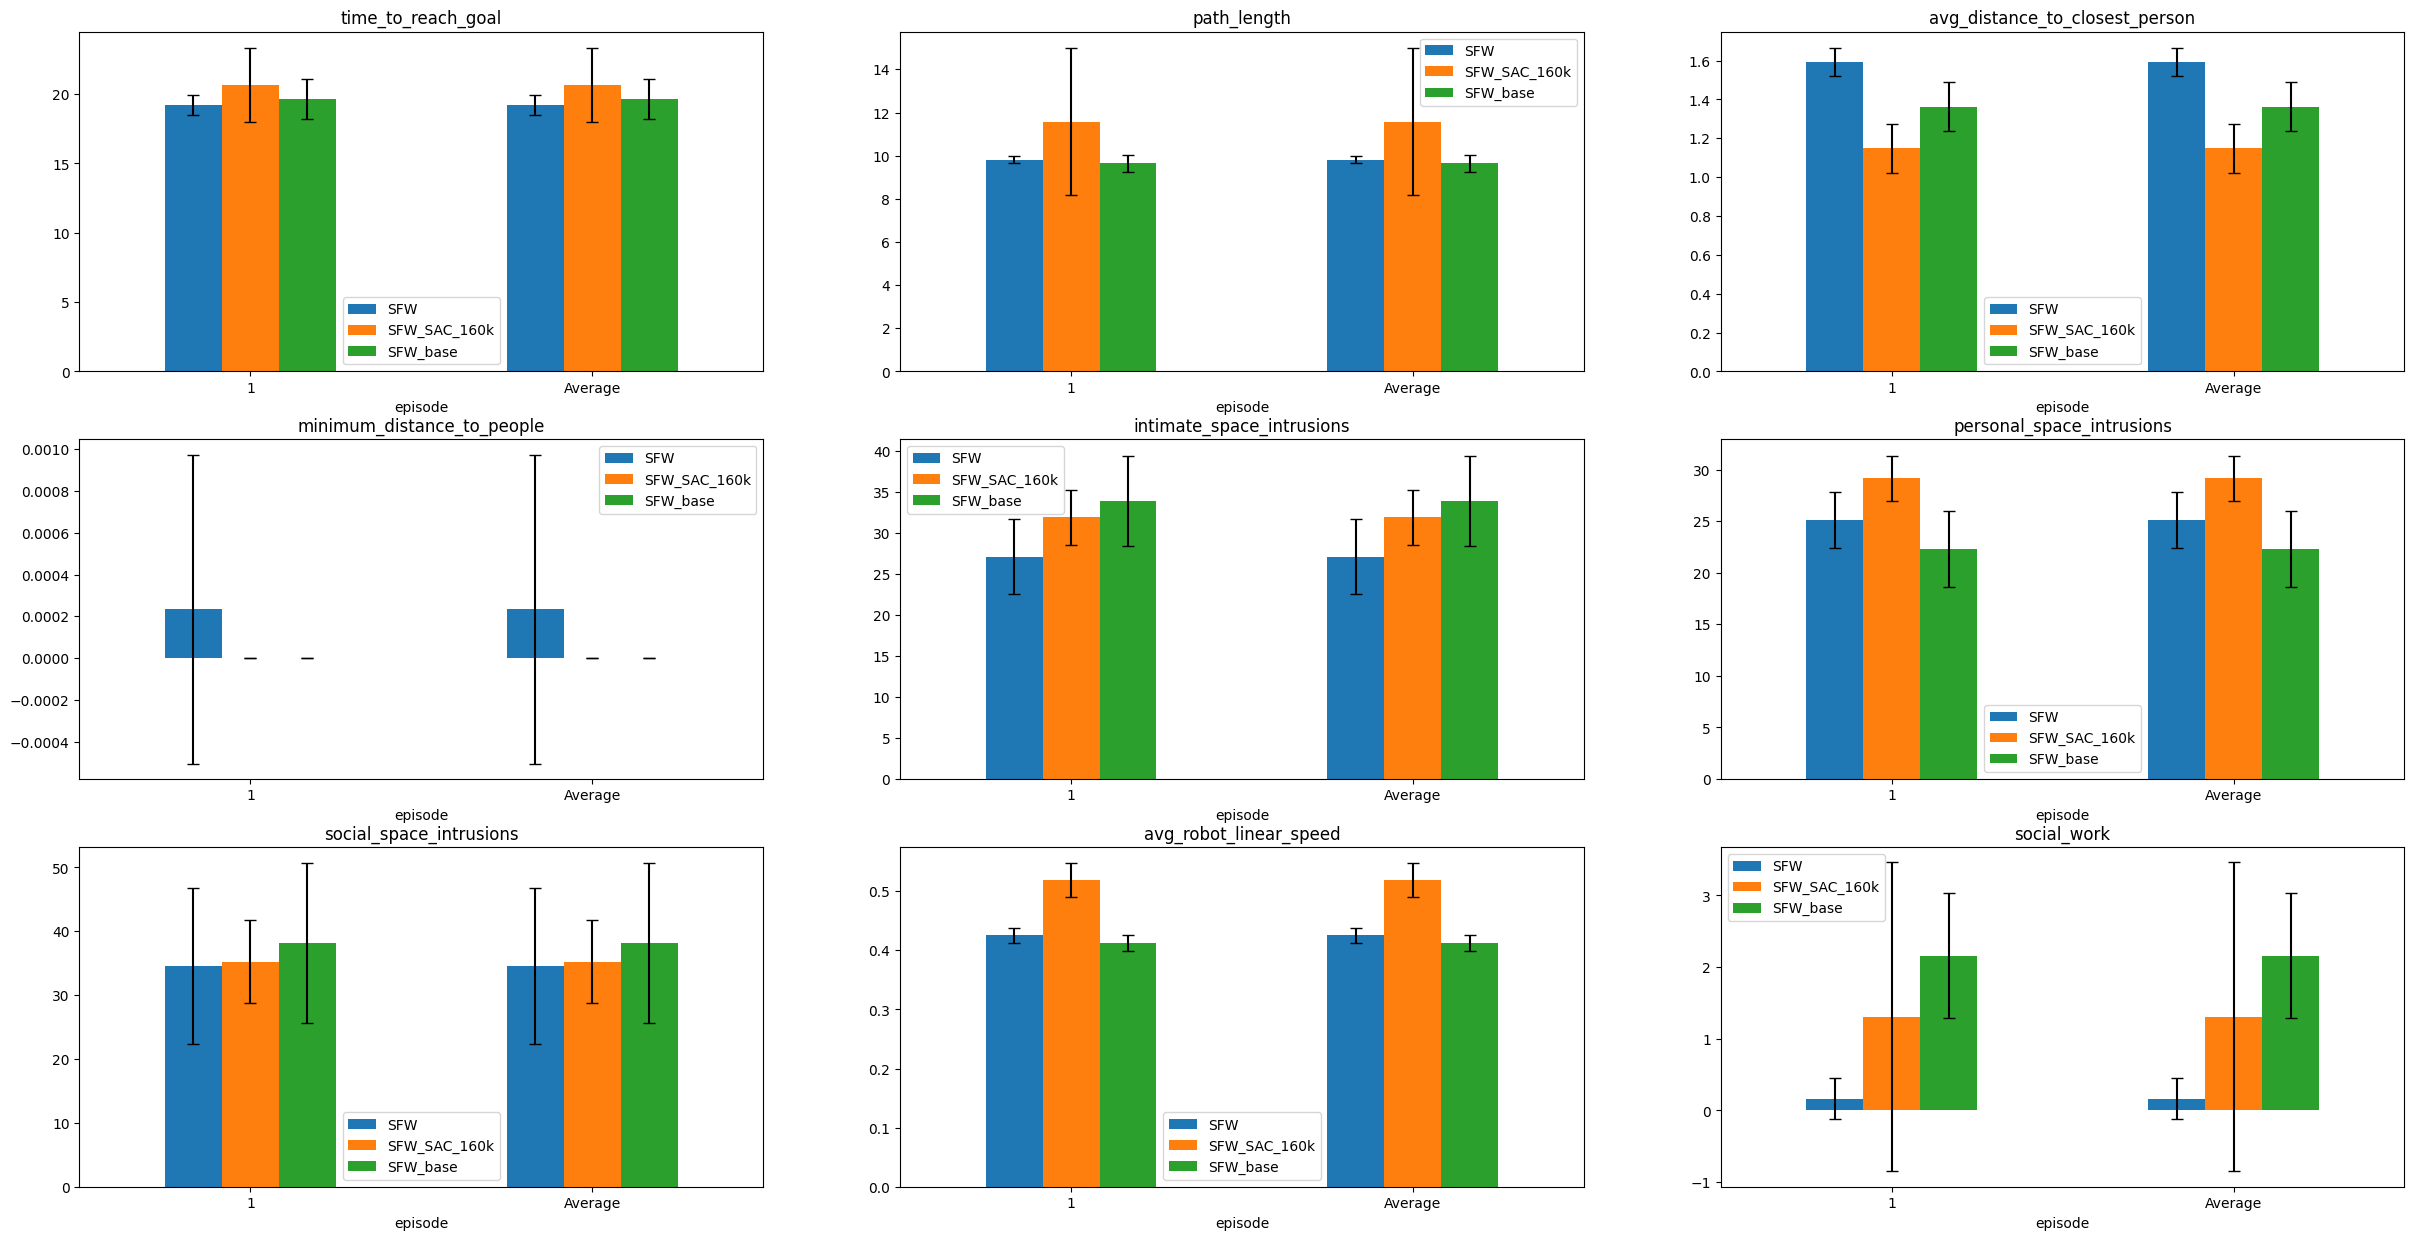

In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_passing_combined, std_passing_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/passing.png")

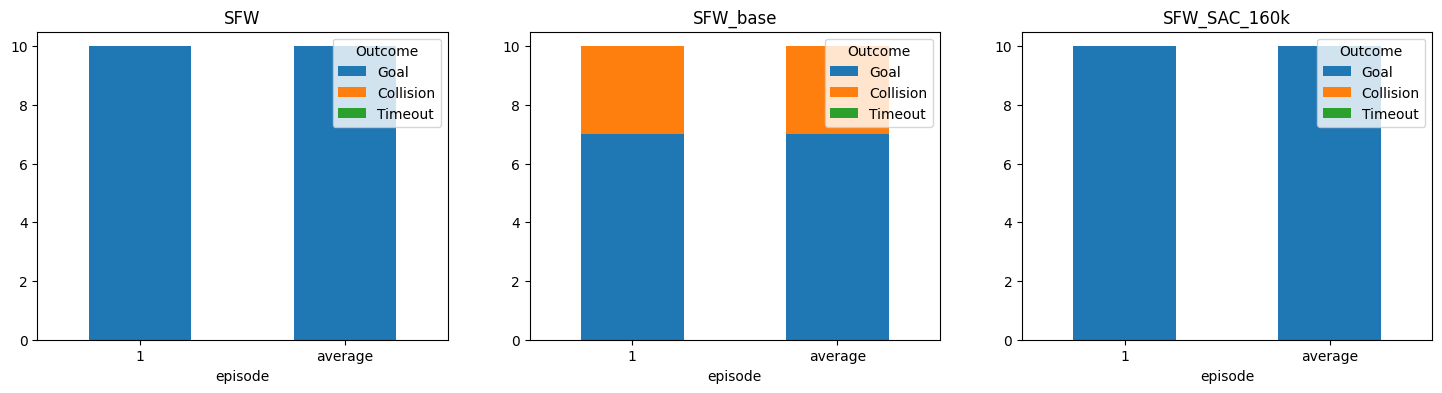

In [ ]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_passing = pd.concat([exp.passing.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.passing.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.passing.get_summary['label'].iloc[0])

fig.savefig('plot/passing_summary.png')

## Overtaking

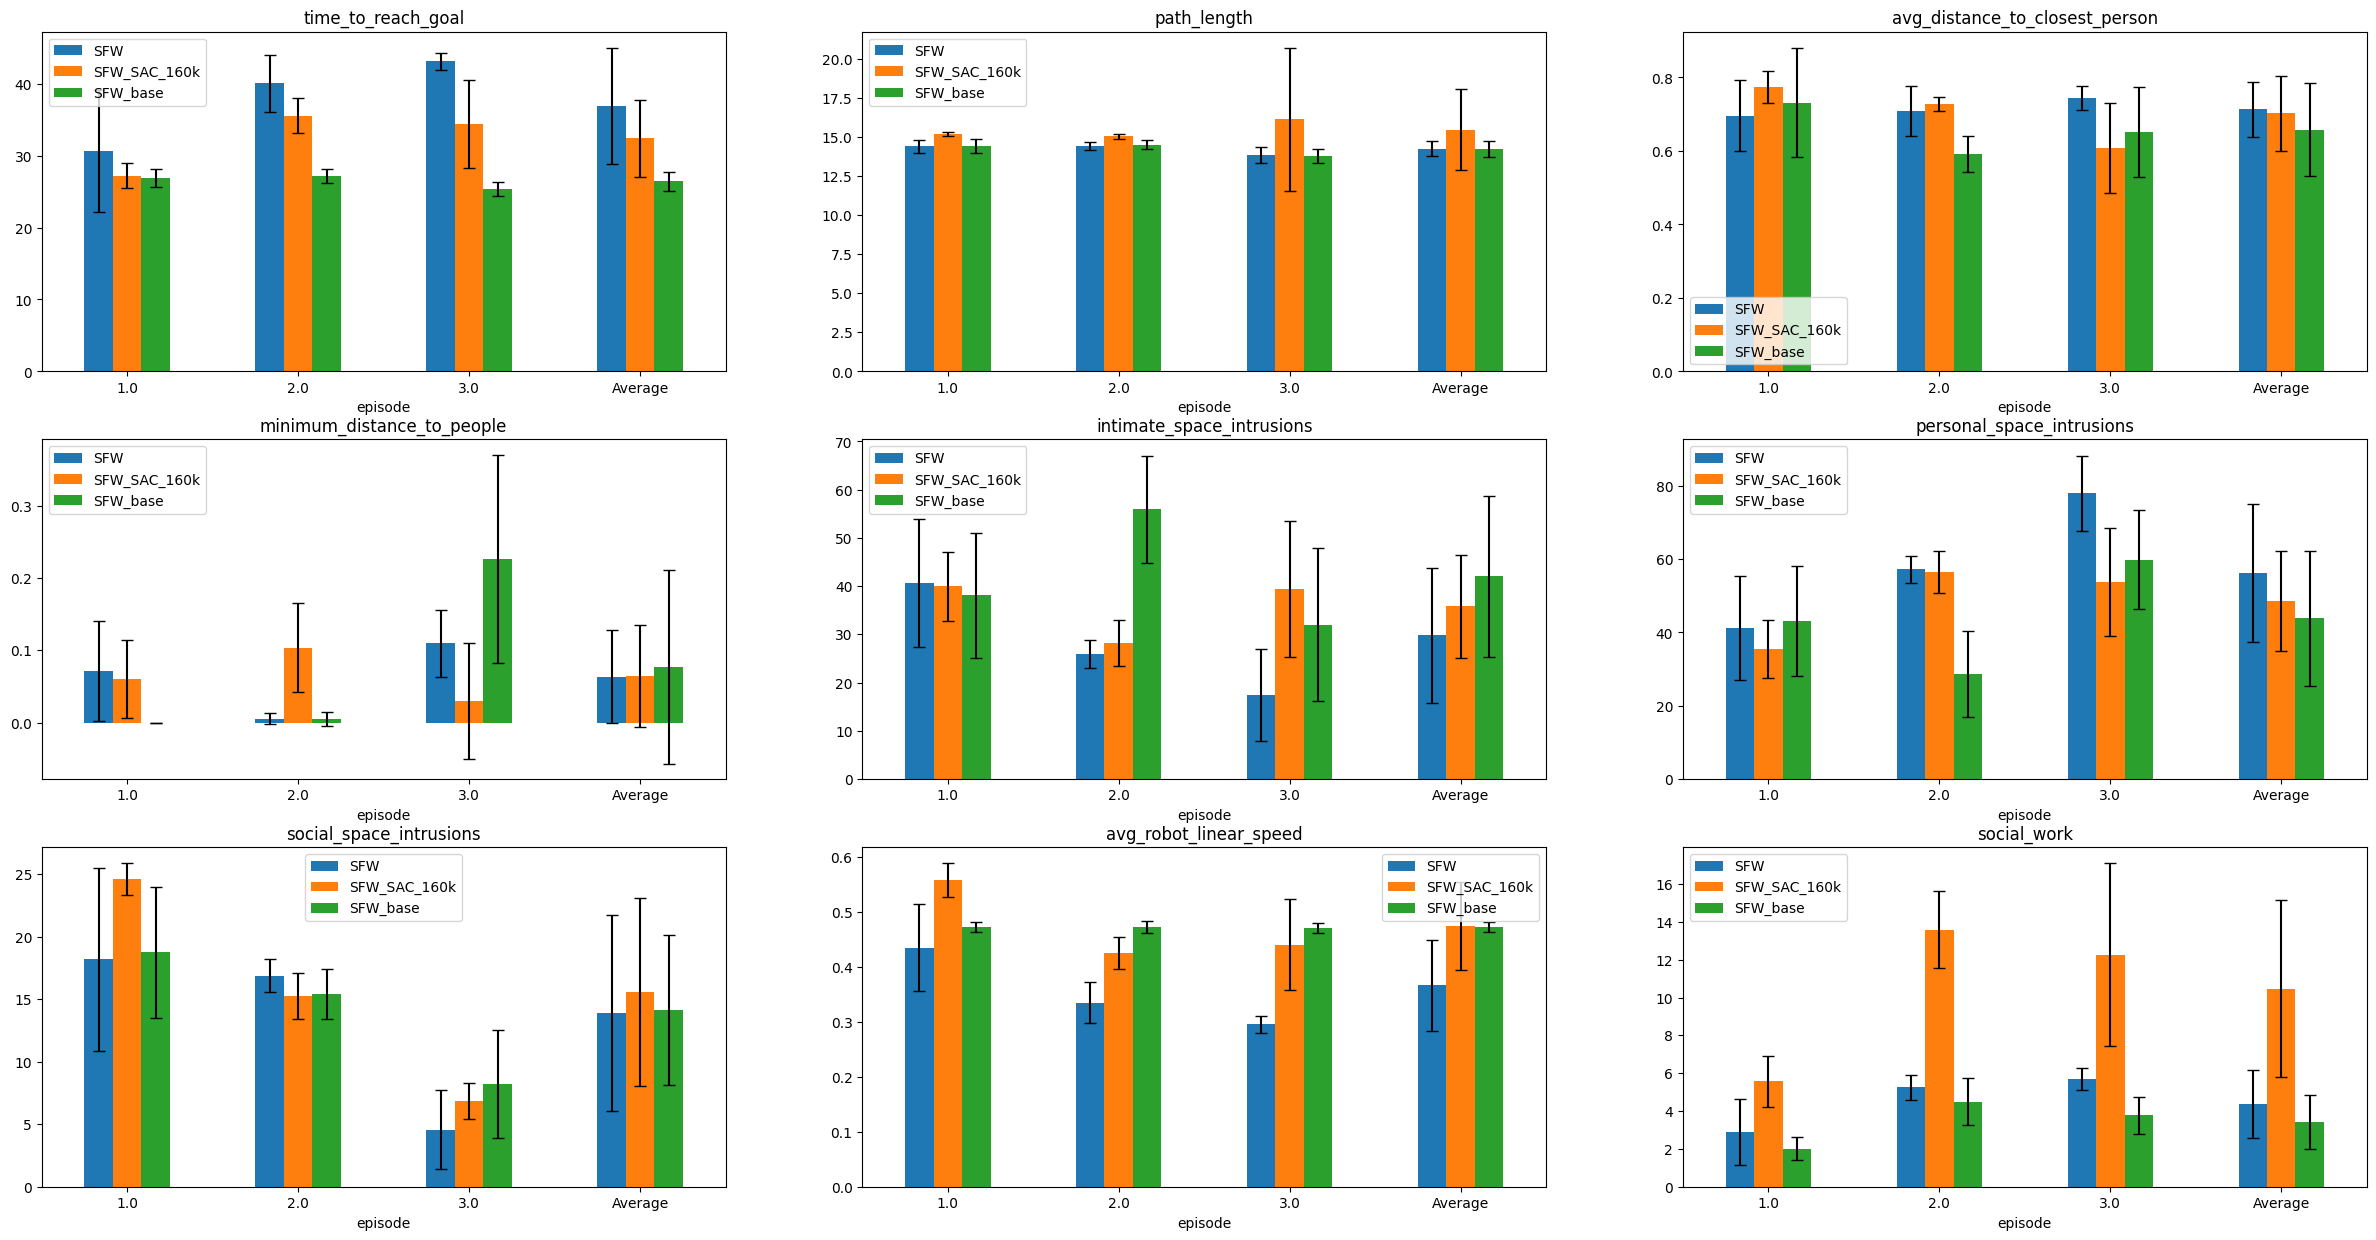

In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_overtaking_combined, std_overtaking_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/overtaking.png")

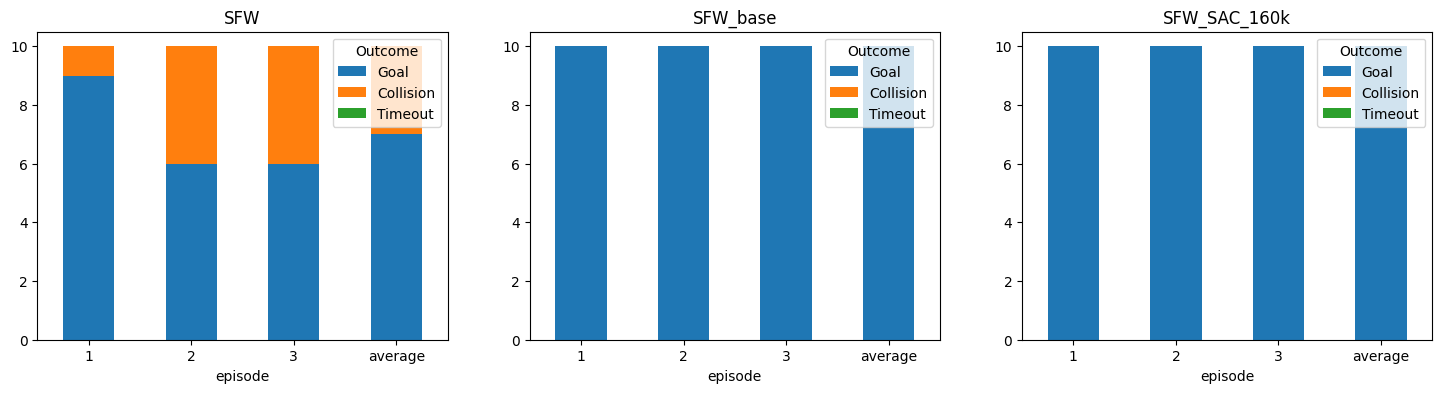

In [ ]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_overtaking = pd.concat([exp.overtaking.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.overtaking.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.overtaking.get_summary['label'].iloc[0])

fig.savefig('plot/overtaking_summary.png')

## Social env

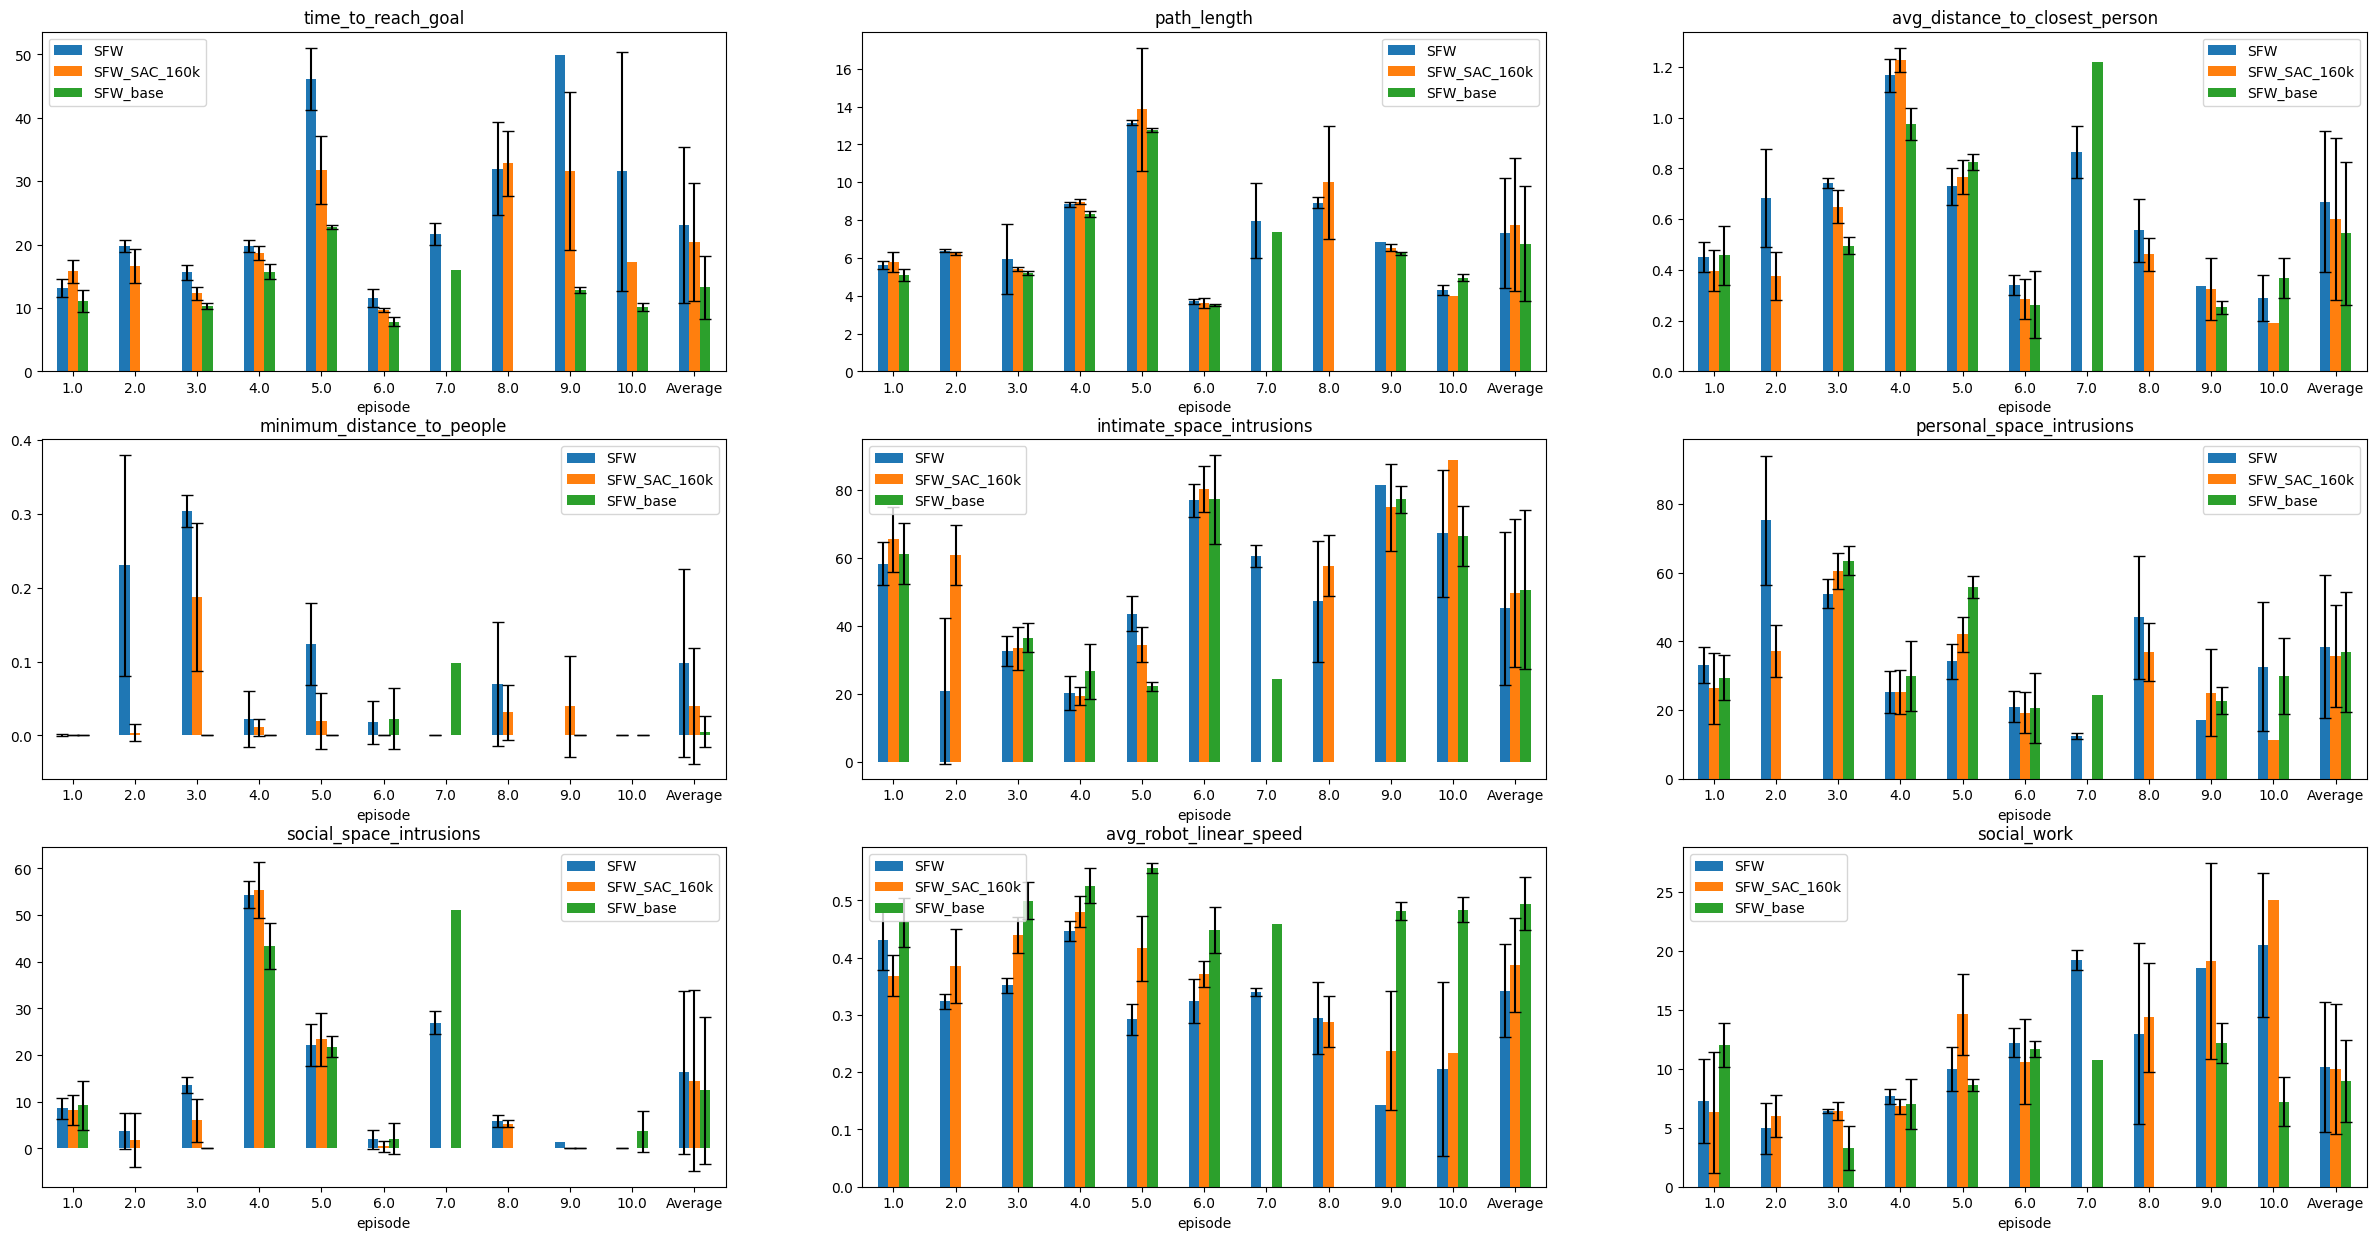

In [45]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_social_env_combined, std_social_env_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/social_env.png")

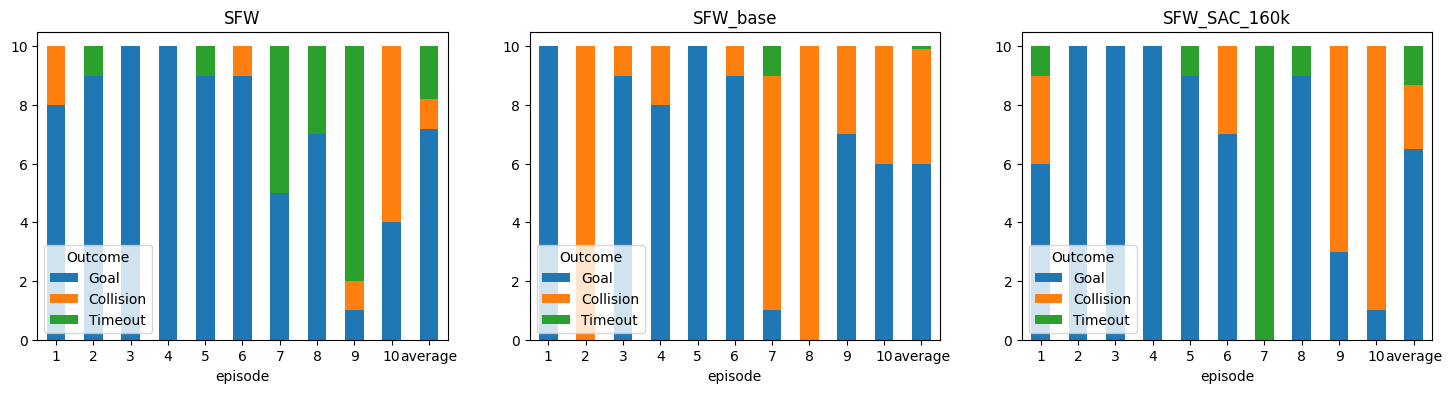

In [46]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_social_env = pd.concat([exp.social_env.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.social_env.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.social_env.get_summary['label'].iloc[0])

fig.savefig('plot/social_env_summary.png')

## Social env7

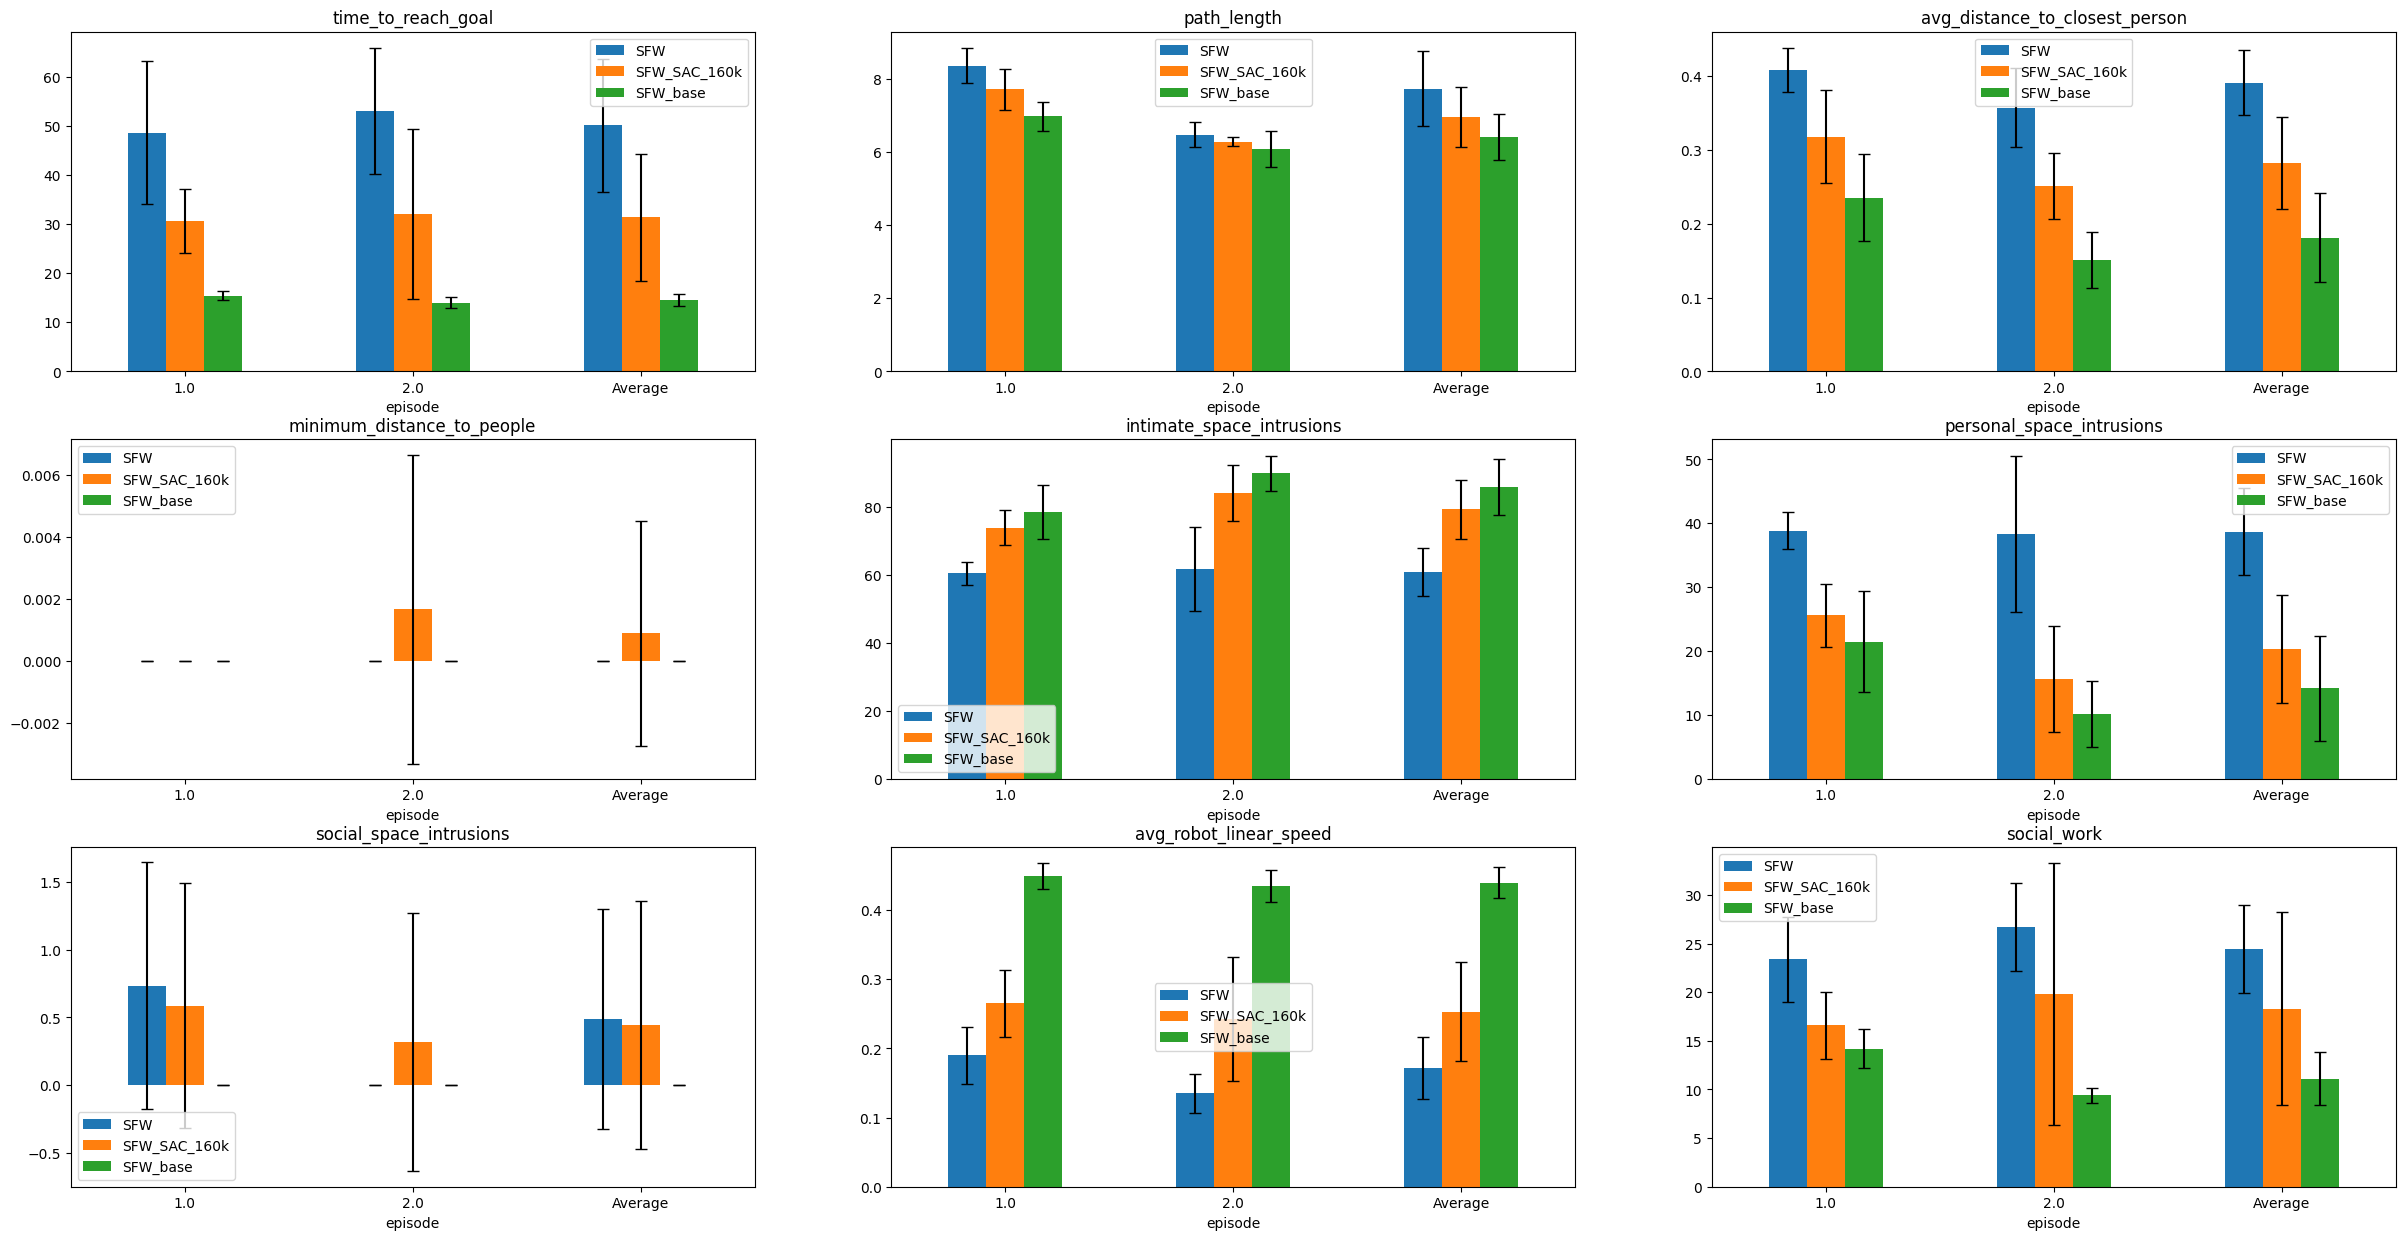

In [48]:
fig, ax = plt.subplots(3, 3, figsize=(30, 15))
for i, attribute in enumerate(attributes_to_plot):
  create_plot(ax[i//3, i%3], mean_social_env7_combined, std_social_env7_combined, attribute)
  ax[i//3, i%3].set_title(attribute)
  ax[i//3, i%3].legend()

fig.savefig("plot/social_env7.png")

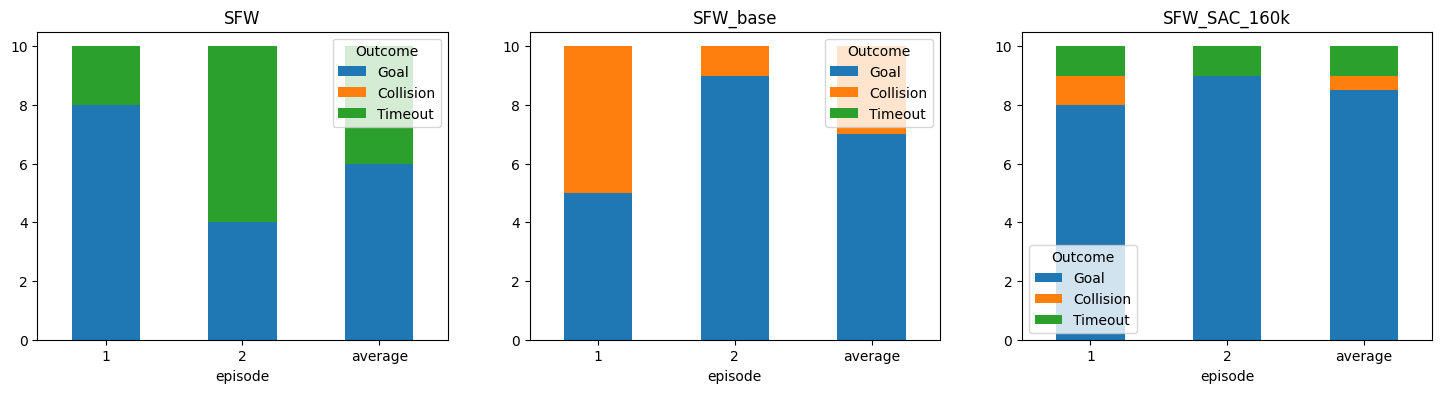

In [49]:
fig, ax = plt.subplots(1, len(experiments), figsize=(6*len(experiments), 4))
# 3 plots for each label
summary_social_env7 = pd.concat([exp.social_env7.get_summary for exp in experiments])
for i,exp in enumerate(experiments):
  exp.social_env7.get_summary.plot.bar(ax=ax[i], x='episode', y=['Goal', 'Collision', 'Timeout'],stacked=True, rot=0)
  ax[i].set_title(exp.social_env7.get_summary['label'].iloc[0])

fig.savefig('plot/social_env7_summary.png')

## Table Single Run


In [50]:
experiments_SAC_160k.social_nav.get_run_from_episode(1, 0)['Outcome'][0]


'Goal'

In [51]:
def get_episode_run_with_outcome(exp_data: ExpData, episode: int, outcome: str='Goal') -> Tuple[pd.DataFrame, int]:
  for i in range(10):
    run = exp_data.get_run_from_episode(episode, i)
    if run['Outcome'].loc[run.index[0]] == outcome:
      if outcome == 'Goal':
        return run , i
      else:
        # if outcome is not Goal, return a series with NaN values
        run = pd.Series([None for i in range(len(run.columns))], index=run.columns)
        run = run.to_frame().T
        run['Outcome'] = outcome
        return run, i
  print(f"Outcome {outcome} not found in episode {episode}")
  return None, None

In [78]:
experiment_list = [experiments_SFW_base, experiments_SFW, experiments_SAC_160k]
# social_nav_episodes = [1,2,4,5,8,9]
social_nav_episodes = [1,3,4,6,7,9]
runs = []
run_to_plot = []

# def get_episodes_runs(
#     experiment_list: List[Experiments],
#     episodes: List[int],
#     outcome: str,
#     experiment_name: str,
#     offset: int = 0,
#     run_number: int=10) -> Tuple[List[pd.DataFrame], List[Dict[str, Any]]]:
#   runs = []
#   for index, episode in enumerate(episodes):
#     for exp in experiment_list:
#       run, run_number = get_episode_run_with_outcome(exp.social_nav, episode, outcome)
#       if run is not None: 
#         run.insert(loc=1, column='method', value=exp.name)
#         run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
#         #rename column episode to environment
#         run.rename(columns={'episode': 'environment'}, inplace=True)
#         run['environment'] = index+1 + offset 
#         runs.append(run)
#       else:
#         runs.append(pd.DataFrame(columns=exp.social_nav.get_df.columns))

#       data = {'method': exp.name,
#               'episode': run_number * 10 + (episode-1),
#               'experiment': experiment_name,
#               'environment': index+1 + offset
#               }
#       run_to_plot.append(data)
#   return runs , run_to_plot

for index, episode in enumerate(social_nav_episodes):
  # print(f"Episode {episode}")
  
  for exp in experiment_list:
    # print(f"Experiment: {exp.name}")
    run, run_number = get_episode_run_with_outcome(exp.social_nav, episode)
    if run is None or (exp.name == 'SFW_base' and episode == 9):
      run , run_number = get_episode_run_with_outcome(exp.social_nav, episode, 'Collision')
    if run is None or (exp.name == 'SFW' and episode == 9):
      run , run_number = get_episode_run_with_outcome(exp.social_nav, episode, 'Timeout')
    if run is not None: 
      # print(f'Select run {run_number+1}')
      run.insert(loc=1, column='method', value=exp.name)
      run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
      #rename column episode to environment
      run.rename(columns={'episode': 'environment'}, inplace=True)
      run['environment'] = index+1 
      runs.append(run)
    else:
      runs.append(pd.DataFrame(columns=exp.social_nav.get_df.columns))

    data = {'method': exp.name,
            'episode': run_number * 10 + (episode-1),
            'experiment': 'social_nav',
            'environment': index+1,
            'outcome': run['Outcome'].loc[run.index[0]]
            }
    run_to_plot.append(data)
  

# crossing_episodes = [1]

# for index, episode in enumerate(crossing_episodes):
#   for exp in experiment_list:
#     # print(f"Experiment: {exp.name}")
#     run, run_number = get_episode_run_with_outcome(exp.crossing, episode)
#     # print(run)
#     if run is not None: 
#       # print(f'Select run {run_number+1}')
#       run.insert(loc=1, column='method', value=exp.name)
#       run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
#       #rename column episode to environment
#       run.rename(columns={'episode': 'environment'}, inplace=True)
#       run['environment'] = index+1 + len(social_nav_episodes) 
#       runs.append(run)
#     else:
#       runs.append(pd.DataFrame(columns=exp.crossing.get_df.columns))

#     data = {'method': exp.name,
#             'episode': (run_number * 2) + (episode-1) ,
#             'experiment': 'crossing',
#             'environment': index+1 + len(social_nav_episodes)
#             }
#     run_to_plot.append(data)

# passing_episodes = [1]

# for index, episode in enumerate(passing_episodes):
#   for exp in experiment_list:
#     # print(f"Experiment: {exp.name}")
#     if exp.name == 'SFW_base' and episode == 1:
#       run, run_number = get_episode_run_with_outcome(exp.passing, episode, 'Collision')
#       # run.loc[run.index[0], :] = '-'
#     else:
#       run, run_number = get_episode_run_with_outcome(exp.passing, episode)
#     # print(run)
#     if run is not None: 
#       # print(f'Select run {run_number+1}')
#       run.insert(loc=1, column='method', value=exp.name)
#       run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
#       #rename column episode to environment
#       run.rename(columns={'episode': 'environment'}, inplace=True)
#       run['environment'] = index+1 + len(social_nav_episodes) + len(crossing_episodes)
#       runs.append(run)
#     else:
#       runs.append(pd.DataFrame(columns=exp.passing.get_df.columns))

    
#     data = {'method': exp.name,
#             'episode': (episode-1) + run_number * 1,
#             'experiment': 'passing',
#             'environment': index+1 + len(social_nav_episodes) + len(crossing_episodes)
#             }
#     run_to_plot.append(data)

# overtaking_episodes = [1]

# for index, episode in enumerate(overtaking_episodes):
#   for exp in experiment_list:
#     # print(f"Experiment: {exp.name}")
#     run, run_number = get_episode_run_with_outcome(exp.overtaking, episode)
#     # print(run)
#     if run is not None: 
#       # print(f'Select run {run_number+1}')
#       run.insert(loc=1, column='method', value=exp.name)
#       if run['Outcome'].loc[run.index[0]] == 'Goal':
#         run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
#       else:
#         run['public_space_intrusions'] = pd.NA
#       #rename column episode to environment
#       run.rename(columns={'episode': 'environment'}, inplace=True)
#       run['environment'] = index+1 + len(social_nav_episodes) + len(crossing_episodes) + len(passing_episodes)
#       runs.append(run)
#     else:
#       runs.append(pd.DataFrame(columns=exp.overtaking.get_df.columns))

social_env_episodes = [2,3,4,8]

for index, episode in enumerate(social_env_episodes):
  for exp in experiment_list:
    # print(f"Experiment: {exp.name}")
    run, run_number = get_episode_run_with_outcome(exp.social_env, episode)
    if run is None or episode == 9:
      run , run_number = get_episode_run_with_outcome(exp.social_env, episode, 'Collision')
    if run is None or (episode == 9 and exp.name == 'SFW'):
      run , run_number = get_episode_run_with_outcome(exp.social_env, episode, 'Timeout')
    if run is not None: 
      # print(f'Select run {run_number+1}')
      run.insert(loc=1, column='method', value=exp.name)
      if run['Outcome'].loc[run.index[0]] == 'Goal':
        run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
      else:
        run['public_space_intrusions'] = pd.NA
      #rename column episode to environment
      run.rename(columns={'episode': 'environment'}, inplace=True)
      run['environment'] = index+1 + len(social_nav_episodes) #+ len(crossing_episodes) + len(passing_episodes)
      runs.append(run)
    else:
      runs.append(pd.DataFrame(columns=exp.social_env.get_df.columns))

      
    data = {'method': exp.name,
            'episode': (episode-1)  + run_number * 10,
            'experiment': 'social_env',
            'environment': index+1 + len(social_nav_episodes), # + len(crossing_episodes) + len(passing_episodes)
            'outcome': run['Outcome'].loc[run.index[0]]
            }
    run_to_plot.append(data)


social_env7_episodes = [1,2]

for index, episode in enumerate(social_env7_episodes):
  for exp in experiment_list:
    # print(f"Experiment: {exp.name}")
    run, run_number = get_episode_run_with_outcome(exp.social_env7, episode)
    if run is None or (episode == 1 and exp.name == 'SFW_base'):
      run , run_number = get_episode_run_with_outcome(exp.social_env7, episode, 'Collision')
    if run is None or (episode == 2 and exp.name == 'SFW'):
      run , run_number = get_episode_run_with_outcome(exp.social_env7, episode, 'Timeout')
    if run is not None: 
      # print(f'Select run {run_number+1}')
      run.insert(loc=1, column='method', value=exp.name)
      if run['Outcome'].loc[run.index[0]] == 'Goal':
        run['public_space_intrusions'] = 100 - run['intimate_space_intrusions'] - run['personal_space_intrusions'] - run['social_space_intrusions']
      else:
        run['public_space_intrusions'] = pd.NA
      #rename column episode to environment
      run.rename(columns={'episode': 'environment'}, inplace=True)
      run['environment'] = index+1 + len(social_nav_episodes) + len(social_env_episodes) #+ len(crossing_episodes) + len(passing_episodes)
      runs.append(run)
    else:
      runs.append(pd.DataFrame(columns=exp.social_env7.get_df.columns))

      
    data = {'method': exp.name,
            'episode': (episode-1)  + run_number * 2,
            'experiment': 'social_env7',
            'environment': index+1 + len(social_nav_episodes) + len(social_env_episodes), # + len(crossing_episodes) + len(passing_episodes)
            'outcome': run['Outcome'].loc[run.index[0]]
            }
    run_to_plot.append(data)

runs_to_plot = pd.DataFrame(run_to_plot)
runs_to_plot.to_csv('data/runs_to_plot.csv', index=False)

runs_df = pd.concat(runs, axis=0)
runs_df.replace({'SFW_SAC_160k': 'SFW SAC', 'SFW_base': 'DWA'}, inplace=True)
attributes_for_table = ['Outcome','time_to_reach_goal', 'path_length', 'avg_robot_linear_speed', 'intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions', 'social_work']

table = runs_df.pivot_table(index=['environment','method'],values=attributes_for_table, sort=False, aggfunc=lambda x: x)
table.sort_values(by=['environment','method'], inplace=True)
# table.to_latex('table.tex', float_format="%.2f", multirow=True, column_format='clccccccc', caption='Performance of the different methods in the different environments', label='tab:performance')
pd.options.display.float_format = "{:,.2f}".format
# table
runs_df


Outcome Goal not found in episode 4
Outcome Goal not found in episode 4
Outcome Goal not found in episode 2
Outcome Goal not found in episode 8


/tmp/ipykernel_2527853/3202547957.py:212: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  runs_df = pd.concat(runs, axis=0)
/tmp/ipykernel_2527853/3202547957.py:213: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  runs_df.replace({'SFW_SAC_160k': 'SFW SAC', 'SFW_base': 'DWA'}, inplace=True)


,environment,method,n_steps,Outcome,time_to_reach_goal,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,intimate_space_intrusions,...,robot_on_person_collision,person_on_robot_collision,time_not_moving,avg_robot_linear_speed,avg_robot_angular_speed,social_force_on_agents,social_force_on_robot,social_work,obstacle_force_on_robot,public_space_intrusions
0,1,DWA,27.00,Goal,7.95,4.16,0.89,1.25,0.00,32.00,...,1.00,3.00,0.00,0.52,0.12,0.12,0.12,0.22,0.00,0.00
0,1,SFW,35.00,Goal,10.66,5.39,1.19,1.29,0.00,30.30,...,0.00,4.00,0.00,0.50,0.12,0.26,0.26,0.49,0.00,0.00
0,1,SFW SAC,39.00,Goal,11.98,5.40,1.58,1.51,0.00,43.24,...,1.00,5.00,0.00,0.45,0.13,3.47,3.47,6.81,0.00,18.92
22,2,DWA,42.00,Goal,12.99,6.01,1.29,0.12,0.00,92.50,...,6.00,13.00,0.00,0.46,0.11,4.70,4.70,9.34,0.00,0.00
2,2,SFW,63.00,Goal,19.98,6.27,1.67,0.55,0.00,24.59,...,3.00,0.00,0.00,0.31,0.09,4.37,4.37,8.69,0.00,0.00
2,2,SFW SAC,41.00,Goal,12.64,6.54,2.33,0.26,0.00,74.36,...,6.00,6.00,0.00,0.51,0.18,5.41,5.41,10.57,0.00,-0.00
0,3,DWA,NaN,Collision,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,3,SFW,NaN,Collision,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,3,SFW SAC,72.00,Goal,22.96,11.61,4.91,0.64,0.00,38.57,...,0.00,6.00,0.00,0.50,0.22,4.40,4.40,8.64,0.00,-0.00
55,4,DWA,69.00,Goal,21.87,12.16,1.38,0.95,0.00,31.34,...,3.00,8.00,0.00,0.55,0.07,9.43,9.43,17.47,0.00,0.00


/tmp/ipykernel_2527853/3390575287.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  runs_df[runs_df['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='method', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
/tmp/ipykernel_2527853/3390575287.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  runs_df[runs_df['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='method', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
/tmp/ipykernel_2527853/3390575287.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases 

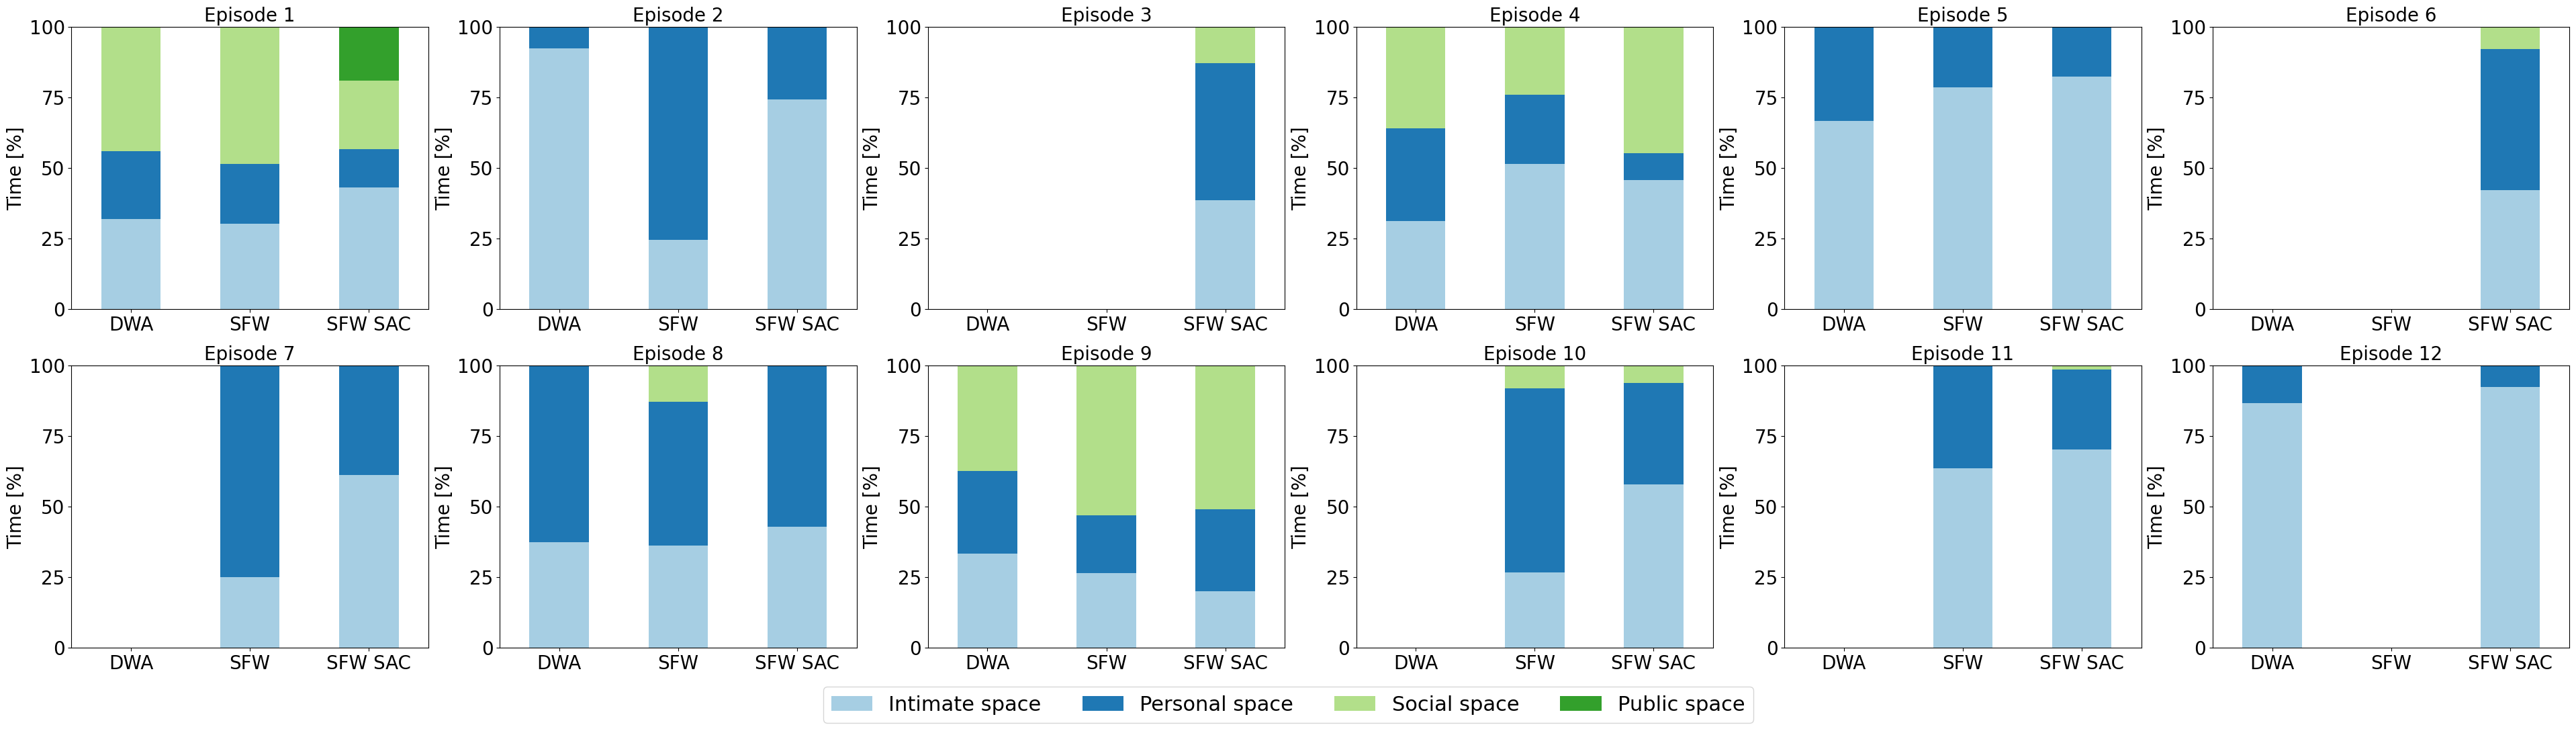

In [79]:


episodes_n = 12
rows = 2
cols = episodes_n // rows
fig, ax = plt.subplots(rows, cols, figsize=(48, episodes_n))
intrusions = ['intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions']
for i in range(episodes_n):
  runs_df[runs_df['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='method', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
  ax[i//cols, i%cols].set_title(f"Episode {i+1}")
  ax[i//cols, i%cols].legend().remove()
  ax[i//cols, i%cols].set_ylabel('Time [%]')
  ax[i//cols, i%cols].set_xlabel('')
  ax[i//cols, i%cols].set_ylim(0, 100)
  ax[i//cols, i%cols].set_yticks([0, 25, 50, 75, 100])
  # modify font size
  for item in ([ax[i//cols, i%cols].title, ax[i//cols, i%cols].xaxis.label, ax[i//cols, i%cols].yaxis.label] +
             ax[i//cols, i%cols].get_xticklabels() + ax[i//cols, i%cols].get_yticklabels()):
    item.set_fontsize(20)


# from matplotlib.
labels = ['Intimate space', 'Personal space', 'Social space', 'Public space']
fig.legend(labels=labels, loc='lower center', ncol=4, fontsize=22)


fig.savefig('plot/proxemics.png')

In [80]:
def parse_outcome(x: pd.Series) -> pd.Series:
  if x.dtype == 'object':
    return x.value_counts()[0] / x.count() * 100
  return x.mean()
  
table_mean = runs_df.pivot_table(index='method',values=attributes_for_table, aggfunc=lambda x: parse_outcome(x), sort=False)
table_mean.rename(columns={'Outcome': 'Success rate (%)'}, inplace=True)
table_mean


/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100
/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100
/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100


,Success rate (%),time_to_reach_goal,path_length,avg_robot_linear_speed,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,public_space_intrusions,social_work
method,,,,,,,,,
DWA,58.33,14.43,7.26,0.50,54.29,28.99,16.73,0.00,8.61
SFW,75.00,26.10,8.65,0.34,40.32,43.42,16.26,0.00,11.81
SFW SAC,100.00,21.14,8.10,0.40,55.93,30.18,12.32,1.58,11.28


/tmp/ipykernel_2527853/431736040.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  table_mean.plot.bar(ax=ax, rot=0, y=intrusions, stacked=True, color=plt.cm.get_cmap('Paired').colors)


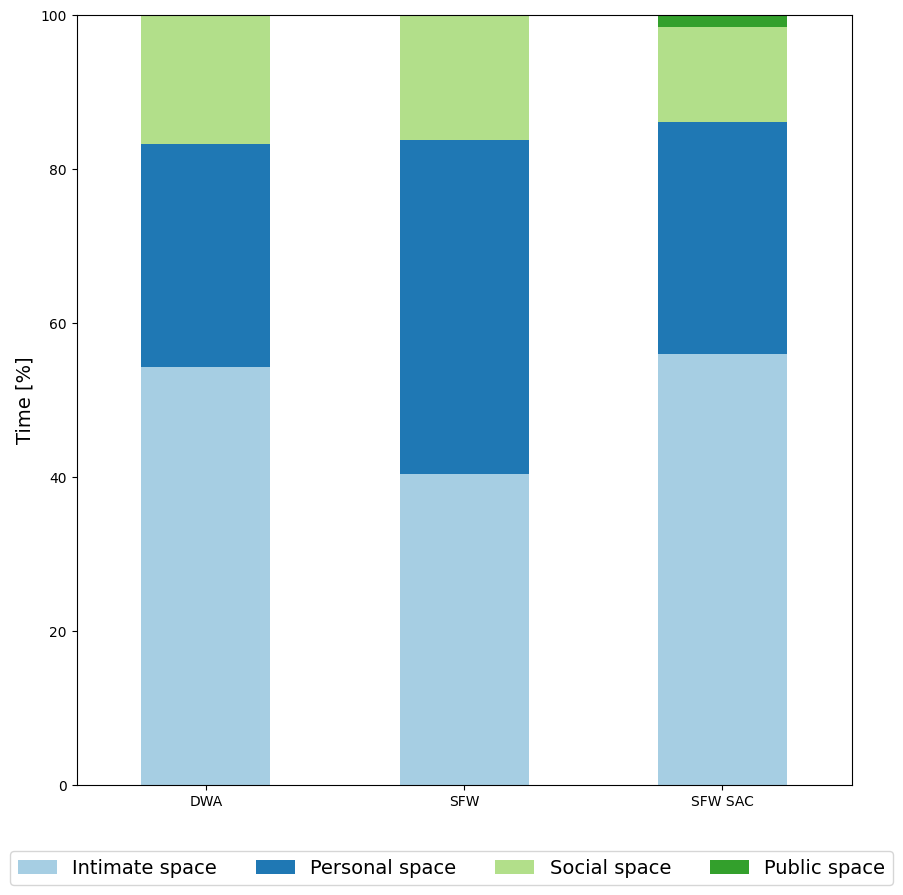

In [81]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
intrusions = ['intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions']
table_mean.plot.bar(ax=ax, rot=0, y=intrusions, stacked=True, color=plt.cm.get_cmap('Paired').colors)
ax.legend().remove()
ax.set_ylabel('Time [%]', fontsize=14)
ax.set_xlabel('')
labels = ['Intimate space', 'Personal space', 'Social space', 'Public space']
fig.legend(labels=labels, loc='lower center', ncol=4, fontsize=14)
fig.savefig('plot/proxemics_average.png')

In [82]:
attributes_for_table_slim = ['Outcome','time_to_reach_goal', 'path_length', 'avg_robot_linear_speed', 'social_work']

table_slim = runs_df.pivot_table(index=['environment','method'],values=attributes_for_table_slim, sort=False, aggfunc=lambda x: x)
table_slim.sort_values(by=['environment','method'], inplace=True)
table_slim.fillna('-', inplace=True)

table_slim

/tmp/ipykernel_2527853/2433005729.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  table_slim.fillna('-', inplace=True)


Outcome time_to_reach_goal path_length  \
environment method                                              
1           DWA           Goal               7.95        4.16   
            SFW           Goal              10.66        5.39   
            SFW SAC       Goal              11.98        5.40   
2           DWA           Goal              12.99        6.01   
            SFW           Goal              19.98        6.27   
            SFW SAC       Goal              12.64        6.54   
3           DWA      Collision                  -           -   
            SFW      Collision                  -           -   
            SFW SAC       Goal              22.96       11.61   
4           DWA           Goal              21.87       12.16   
            SFW           Goal              46.96       12.29   
            SFW SAC       Goal              27.29       12.32   
5           DWA           Goal              16.62        9.18   
            SFW           Goal              32.30        9.87   
            SFW SAC       Goal              39.27        9.40   
6           DWA      Collision                  -           -   
            SFW        Timeout                  -           -   
            SFW SAC       Goal              20.93        8.70   
7           DWA      Collision                  -           -   
            SFW           Goal              20.95        6.46   
            SFW SAC       Goal              15.98        6.29   
8           DWA           Goal              10.30        5.20   
            SFW           Goal              18.49       11.27   
            SFW SAC       Goal              11.32        5.34   
9           DWA           Goal              16.60        8.30   
            SFW           Goal              20.98        8.80   
            SFW SAC       Goal              17.97        8.97   
10          DWA      Collision                  -           -   
            SFW           Goal              24.63        9.11   
            SFW SAC       Goal              27.32        9.13   
11          DWA      Collision                  -           -   
            SFW           Goal              39.97        8.44   
            SFW SAC       Goal              24.31        7.10   
12          DWA           Goal              14.65        5.79   
            SFW        Timeout                  -           -   
            SFW SAC       Goal              21.65        6.45   

                    avg_robot_linear_speed social_work  
environment method                                      
1           DWA                       0.52        0.22  
            SFW                       0.50        0.49  
            SFW SAC                   0.45        6.81  
2           DWA                       0.46        9.34  
            SFW                       0.31        8.69  
            SFW SAC                   0.51       10.57  
3           DWA                          -           -  
            SFW                          -           -  
            SFW SAC                   0.50        8.64  
4           DWA                       0.55       17.47  
            SFW                       0.26       26.62  
            SFW SAC                   0.45       12.32  
5           DWA                       0.55       10.85  
            SFW                       0.31       22.21  
            SFW SAC                   0.24       23.82  
6           DWA                          -           -  
            SFW                          -           -  
            SFW SAC                   0.41       12.69  
7           DWA                          -           -  
            SFW                       0.31        7.17  
            SFW SAC                   0.39        4.14  
8           DWA                       0.50        5.33  
            SFW                       0.35        6.41  
            SFW SAC                   0.47        5.91  
9           DWA                       0.50        7.80  
            S

In [83]:
attributes_for_table_slim = ['Outcome','time_to_reach_goal', 'path_length', 'avg_robot_linear_speed', 'social_work']

table_mean_slim = runs_df.pivot_table(index='method',values=attributes_for_table_slim, aggfunc=lambda x: parse_outcome(x), sort=False)
table_mean_slim.rename(columns={'Outcome': 'Success rate (%)'}, inplace=True)
table_mean_slim


/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100
/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100
/tmp/ipykernel_2527853/27922197.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  return x.value_counts()[0] / x.count() * 100


,Success rate (%),time_to_reach_goal,path_length,avg_robot_linear_speed,social_work
method,,,,,
DWA,58.33,14.43,7.26,0.50,8.61
SFW,75.00,26.10,8.65,0.34,11.81
SFW SAC,100.00,21.14,8.10,0.40,11.28


In [96]:
# from the 

a =mean_social_nav_combined.join(summary_social_nav.set_index(['label','episode']), on=['label','episode'])
# b =mean_crossing_combined.join(summary_crossing.set_index(['label','episode']), on=['label','episode'])
# c =mean_passing_combined.join(summary_passing.set_index(['label','episode']), on=['label','episode'])
# d =mean_overtaking_combined.join(summary_overtaking.set_index(['label','episode']), on=['label','episode'])
b =mean_social_env_combined.join(summary_social_env.set_index(['label','episode']), on=['label','episode'])
c =mean_social_env7_combined.join(summary_social_env7.set_index(['label','episode']), on=['label','episode'])
mean_statistics = [a,b,c]
# episodes_names = ['Social Navigation', 'Crossing', 'Passing', 'Overtaking']
episodes_names = ['Social Nav', 'Social Env', 'Social Env 7']
# episodes_selected = [social_nav_episodes, crossing_episodes, passing_episodes, overtaking_episodes]
episodes_selected = [social_nav_episodes, social_env_episodes, social_env7_episodes]

environments_episodes = []
for mean_statistic,episodes_name, episodes in zip(mean_statistics,episodes_names, episodes_selected):
  for i, episode in enumerate(episodes):
    environments_episodes.append(mean_statistic[mean_statistic['episode'] == episode])
    offset = 0
    # if episodes_name == 'Crossing':
    #   offset = len(social_nav_episodes)
    # elif episodes_name == 'Passing':
    #   offset = len(social_nav_episodes) + len(crossing_episodes)
    # elif episodes_name == 'Overtaking':
    #   offset = len(social_nav_episodes) + len(crossing_episodes) + len(passing_episodes)
    if episodes_name == 'Social Env':
      offset = len(social_nav_episodes)
    elif episodes_name == 'Social Env 7':
      offset = len(social_nav_episodes) + len(social_env_episodes)
    environments_episodes[-1]['environment'] = i+1+ offset


environments_episodes = pd.concat(environments_episodes, axis=0)
environments_episodes['Success rate'] = environments_episodes['Goal'] / (environments_episodes['Goal'] + environments_episodes['Collision'] + environments_episodes['Timeout']) * 100
environments_episodes['SW per step'] = environments_episodes['social_work'] / environments_episodes['n_steps']

/tmp/ipykernel_2527853/4081631397.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  environments_episodes[-1]['environment'] = i+1+ offset
/tmp/ipykernel_2527853/4081631397.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  environments_episodes[-1]['environment'] = i+1+ offset
/tmp/ipykernel_2527853/4081631397.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: 

In [97]:

attributes_for_table_slim = ['Success rate','time_to_reach_goal', 'path_length', 'avg_robot_linear_speed', 'social_work', 'SW per step']
# filtered_environments_episodes= environments_episodes[environments_episodes['label'].isin(['SFW_base', 'SFW', 'SAC_NR_2_2.0f'])]
filtered_environments_episodes= environments_episodes[environments_episodes['label'].isin(['SFW_base', 'SFW', 'SFW_SAC_160k'])]
filtered_environments_episodes['public_space_intrusions'] = 100 - filtered_environments_episodes['intimate_space_intrusions'] - filtered_environments_episodes['personal_space_intrusions'] - filtered_environments_episodes['social_space_intrusions']
# filtered_environments_episodes.replace({'SAC_NR_2_2.0f': 'SFW-SAC', 'SFW_base': 'DWA'}, inplace=True)
filtered_environments_episodes.replace({'SFW_SAC_160k': 'SFW-SAC', 'SFW_base': 'DWA'}, inplace=True)
pivot_table = filtered_environments_episodes.pivot_table(index=['environment','label'], values=attributes_for_table_slim, aggfunc=lambda x: x, sort=False)
pivot_table.rename(columns={'Success rate': 'Success rate [%]'}, inplace=True)
pivot_table.rename(columns={'time_to_reach_goal': 'Time [s]'}, inplace=True)
pivot_table.rename(columns={'path_length': 'PL [m]'}, inplace=True)
pivot_table.rename(columns={'avg_robot_linear_speed': 'Speed [m/s]'}, inplace=True)
pivot_table.rename(columns={'social_work': 'SW'}, inplace=True)
pivot_table.fillna('-', inplace=True)
pivot_table.sort_values(by=['environment','label'], inplace=True)
pivot_table


/tmp/ipykernel_2527853/500943092.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filtered_environments_episodes.replace({'SFW_SAC_160k': 'SFW-SAC', 'SFW_base': 'DWA'}, inplace=True)


Success rate [%]  Time [s]  PL [m]  Speed [m/s]    SW  \
environment label                                                            
1           DWA                100.00     11.65    5.68         0.49  1.05   
            SFW                100.00     12.48    6.04         0.49  1.75   
            SFW-SAC            100.00     12.21    5.91         0.48  2.15   
2           DWA                 20.00     12.32    6.21         0.50  6.76   
            SFW                 70.00     20.43    6.42         0.31  7.18   
            SFW-SAC            100.00     13.08    6.36         0.49  9.35   
3           SFW-SAC             70.00     23.26   11.29         0.48  8.61   
4           DWA                 20.00     21.71   12.21         0.56 17.21   
            SFW                 60.00     37.91   12.65         0.38 19.23   
            SFW-SAC             70.00     26.20   12.60         0.48 16.48   
5           DWA                 50.00     19.53    9.47         0.49 17.11   
            SFW                 60.00     29.34    9.54         0.34 31.90   
            SFW-SAC             70.00     33.28    9.47         0.30 24.49   
6           DWA                 50.00     19.57    8.87         0.46 16.02   
            SFW                 40.00     44.24   10.75         0.25 22.39   
            SFW-SAC             90.00     23.60    8.75         0.37 13.45   
7           SFW                 90.00     19.83    6.38         0.32  4.95   
            SFW-SAC            100.00     16.59    6.25         0.39  5.98   
8           DWA                 90.00     10.35    5.21         0.50  3.29   
            SFW                100.00     15.64    5.95         0.35  6.43   
            SFW-SAC            100.00     12.32    5.42         0.44  6.40   
9           DWA                 80.00     15.75    8.32         0.53  7.02   
            SFW                100.00     19.77    8.84         0.45  7.68   
            SFW-SAC            100.00     18.62    8.98         0.48  6.82   
10          SFW                 70.00     31.96    8.91         0.29 12.99   
            SFW-SAC             90.00     32.84    9.99         0.29 14.38   
11          DWA                 50.00     15.45    6.98         0.45 14.21   
            SFW                 80.00     48.58    8.37         0.19 23.39   
            SFW-SAC             80.00     30.60    7.72         0.27 16.59   
12          DWA                 90.00     13.98    6.09         0.43  9.39   
            SFW                 40.00     53.04    6.48         0.14 26.68   
            SFW-SAC             90.00     32.01    6.29         0.24 19.81   

                     SW per step  
environment label                 
1           DWA             0.03  
            SFW             0.04  
            SFW-SAC         0.05  
2           DWA             0.17  
            SFW             0.11  
            SFW-SAC         0.22  
3           SFW-SAC         0.12  
4           DWA             0.25  
            SFW             0.16  
            SFW-SAC         0.20  
5           DWA             0.28  
            SFW             0.34  
            SFW-SAC         0.24  
6           DWA             0.26  
            SFW             0.16  
            SFW-SAC         0.18  
7           SFW             0.08  
            SFW-SAC         0.11  
8           DWA             0.10  
            SFW             0.13  
            SFW-SAC         0.16  
9           DWA             0.14  
            SFW             0.12  
            SFW-SAC         0.12  
10          SFW             0.13  
            SFW-SAC         0.14  
11          DWA             0.29  
            SFW             0.16  
            SFW-SAC         0.17  
12          DWA             0.21  
            SFW             0.16  
            SFW-SAC         0.20

In [93]:
# table_mean_slim = runs_df.pivot_table(index='method',values=attributes_for_table_slim, aggfunc=lambda x: parse_outcome(x), sort=False)
pivot_table_mean = filtered_environments_episodes.pivot_table(index=['label'], values=attributes_for_table_slim, aggfunc=lambda x: x.mean(), sort=False)
pivot_table_mean.rename(columns={'Success rate': 'Success rate [%]'}, inplace=True)
pivot_table_mean.rename(columns={'time_to_reach_goal': 'Time [s]'}, inplace=True)
pivot_table_mean.rename(columns={'path_length': 'PL [m]'}, inplace=True)
pivot_table_mean.rename(columns={'avg_robot_linear_speed': 'Speed [m/s]'}, inplace=True)
pivot_table_mean.rename(columns={'social_work': 'SW'}, inplace=True)
pivot_table_mean.sort_values(by=['label'], inplace=True)
pivot_table_mean

,Success rate [%],Time [s],PL [m],Speed [m/s],SW,SW per step
label,,,,,,
DWA,58.57,15.84,8.00,0.50,9.78,0.17
SFW,76.67,25.73,8.39,0.35,12.72,0.14
SFW-SAC,89.00,21.20,8.50,0.42,10.81,0.15


In [115]:
experiment_list = [experiments_SFW_base, experiments_SFW, experiments_SAC_160k]
labels = ['DWA', 'SFW', 'SFW-SAC']
tot_exp = []
for exp,label in zip(experiment_list,labels):
  x1 =exp.social_nav.df.where(exp.social_nav.df['episode'].isin(social_nav_episodes)).dropna()
  x1 = x1.where(x1['Outcome'] == 'Goal').dropna()
  x1['label'] = label
  x1['sw_per_step'] = x1['social_work'] / x1['n_steps']
  tot_exp.append(x1)
  x2 =exp.social_env.df.where(exp.social_env.df['episode'].isin(social_env_episodes)).dropna()
  x2 = x2.where(x2['Outcome'] == 'Goal').dropna()
  x2['label'] = label
  x2['sw_per_step'] = x2['social_work'] / x2['n_steps']
  tot_exp.append(x2)
  x3 =exp.social_env7.df.where(exp.social_env7.df['episode'].isin(social_env7_episodes)).dropna()
  x3 = x3.where(x3['Outcome'] == 'Goal').dropna()
  x3['label'] = label
  x3['sw_per_step'] = x3['social_work'] / x3['n_steps']
  tot_exp.append(x3)

  
tot_exp = pd.concat(tot_exp, axis=0)
attributes_for_table_slim_x = ['time_to_reach_goal', 'path_length', 'avg_robot_linear_speed', 'social_work', 'sw_per_step']

tot_exp.pivot_table(index=['label'], values=attributes_for_table_slim_x, aggfunc=lambda x: x.mean(), sort=False)

,time_to_reach_goal,path_length,avg_robot_linear_speed,social_work,sw_per_step
label,,,,,
DWA,14.59,7.06,0.48,8.46,0.16
SFW,27.23,7.93,0.34,12.77,0.14
SFW-SAC,22.15,8.02,0.40,11.47,0.16


/tmp/ipykernel_2527853/4008129104.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plot_envs[plot_envs['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='label', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
/tmp/ipykernel_2527853/4008129104.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plot_envs[plot_envs['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='label', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
/tmp/ipykernel_2527853/4008129104.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor rel

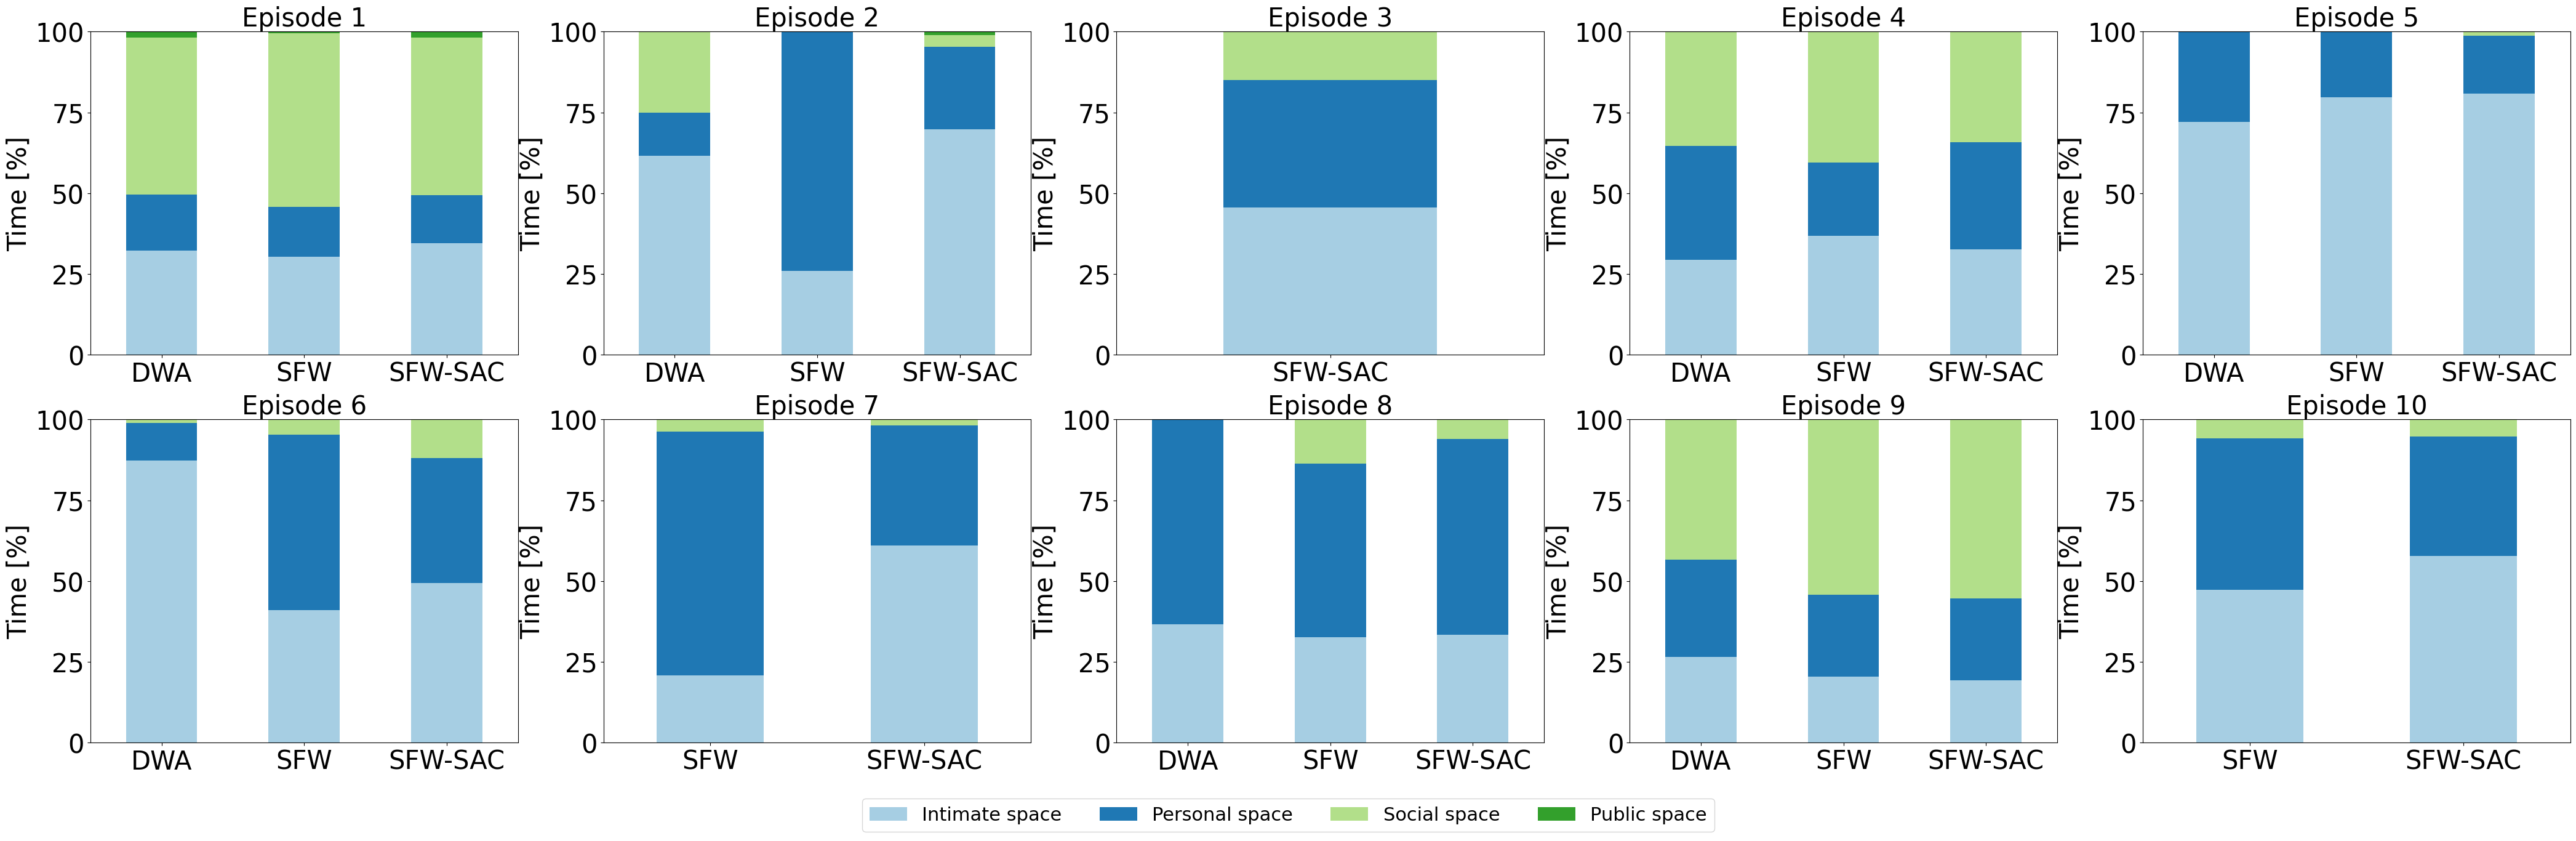

In [87]:
environments_episodes
episodes_n = 10 
rows = 2
cols = episodes_n // rows
fig, ax = plt.subplots(rows, cols, figsize=(52, 1.5*episodes_n))
plot_envs = filtered_environments_episodes.sort_values(by=['environment','label'])
intrusions = ['intimate_space_intrusions', 'personal_space_intrusions', 'social_space_intrusions', 'public_space_intrusions']
for i in range(episodes_n):
  plot_envs[plot_envs['environment'] == i+1].plot.bar(ax=ax[i//cols, i%cols], x='label', y=intrusions, stacked=True, rot=0, color=plt.cm.get_cmap('Paired').colors)
  ax[i//cols, i%cols].set_title(f"Episode {i+1}")
  ax[i//cols, i%cols].legend().remove()
  ax[i//cols, i%cols].set_ylabel('Time [%]')
  ax[i//cols, i%cols].set_xlabel('')
  ax[i//cols, i%cols].set_ylim(0, 100)
  ax[i//cols, i%cols].set_yticks([0, 25, 50, 75, 100])
  # modify font size
  for item in ([ax[i//cols, i%cols].title, ax[i//cols, i%cols].xaxis.label, ax[i//cols, i%cols].yaxis.label] +
             ax[i//cols, i%cols].get_xticklabels() + ax[i//cols, i%cols].get_yticklabels()):
    item.set_fontsize(30)  
  
    


# from matplotlib.
labels = ['Intimate space', 'Personal space', 'Social space', 'Public space']
fig.legend(labels=labels, loc='lower center', ncol=4, fontsize=22)


fig.savefig('plot/proxemics.png', bbox_inches='tight')

In [88]:
filtered_environments_episodes

,episode,n_steps,time_to_reach_goal,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,...,social_force_on_robot,social_work,obstacle_force_on_robot,label,Collision,Goal,Timeout,environment,Success rate,public_space_intrusions
0,1.00,41.20,12.48,6.04,1.57,1.37,0.00,30.25,15.55,53.60,...,0.88,1.75,0.00,SFW,0.00,10.00,0.00,1,100.00,0.60
0,1.00,38.10,11.65,5.68,1.13,1.37,0.00,32.19,17.48,48.46,...,0.54,1.05,0.00,DWA,0.00,10.00,0.00,1,100.00,1.88
0,1.00,39.70,12.21,5.91,1.27,1.35,0.00,34.61,14.68,48.81,...,1.09,2.15,0.00,SFW-SAC,0.00,10.00,0.00,1,100.00,1.89
2,3.00,65.57,20.43,6.42,1.88,0.58,0.09,25.99,74.01,0.00,...,3.61,7.18,0.00,SFW,3.00,7.00,0.00,2,70.00,0.00
2,3.00,40.00,12.32,6.21,1.21,0.70,0.01,61.53,13.47,25.00,...,3.40,6.76,0.00,DWA,8.00,2.00,0.00,2,20.00,0.00
2,3.00,42.30,13.08,6.36,1.95,0.39,0.00,69.81,25.49,3.53,...,4.76,9.35,0.00,SFW-SAC,0.00,10.00,0.00,2,100.00,1.18
3,4.00,72.86,23.26,11.29,4.47,0.64,0.00,45.64,39.33,15.03,...,4.41,8.61,0.00,SFW-SAC,3.00,7.00,0.00,3,70.00,0.00
4,6.00,117.00,37.91,12.65,4.82,0.97,0.01,36.75,22.75,40.51,...,10.00,19.23,0.00,SFW,2.00,6.00,2.00,4,60.00,0.00
4,6.00,68.50,21.71,12.21,1.54,0.96,0.00,29.31,35.36,35.33,...,9.26,17.21,0.00,DWA,8.00,2.00,0.00,4,20.00,0.00
5,6.00,81.71,26.20,12.60,3.86,0.89,0.01,32.59,33.12,34.29,...,8.42,16.48,0.00,SFW-SAC,3.00,7.00,0.00,4,70.00,0.00


In [89]:
runs_to_plot

,method,episode,experiment,environment,outcome
0,SFW_base,0,social_nav,1,Goal
1,SFW,0,social_nav,1,Goal
2,SFW_SAC_160k,0,social_nav,1,Goal
3,SFW_base,22,social_nav,2,Goal
4,SFW,2,social_nav,2,Goal
5,SFW_SAC_160k,2,social_nav,2,Goal
6,SFW_base,3,social_nav,3,Collision
7,SFW,3,social_nav,3,Collision
8,SFW_SAC_160k,13,social_nav,3,Goal
9,SFW_base,55,social_nav,4,Goal


In [90]:
experiments_SAC_160k.social_nav.df
experiments_SAC_160k.social_nav.get_episode(4)

,episode,n_steps,Outcome,time_to_reach_goal,path_length,cumulative_heading_changes,avg_distance_to_closest_person,minimum_distance_to_people,intimate_space_intrusions,personal_space_intrusions,social_space_intrusions,robot_on_person_collision,person_on_robot_collision,time_not_moving,avg_robot_linear_speed,avg_robot_angular_speed,social_force_on_agents,social_force_on_robot,social_work,obstacle_force_on_robot
3,4,14,Collision,3.66,1.80,0.27,0.36,0.00,58.33,41.67,0.00,0,4,0.00,0.47,0.09,3.08,3.08,6.05,0.00
13,4,72,Goal,22.96,11.61,4.91,0.64,0.00,38.57,48.57,12.86,0,6,0.00,0.50,0.22,4.40,4.40,8.64,0.00
23,4,72,Goal,22.98,11.77,4.67,0.65,0.00,40.00,45.71,14.29,0,5,0.00,0.51,0.21,4.14,4.14,8.06,0.00
33,4,15,Collision,3.99,2.02,0.44,0.33,0.00,61.54,38.46,0.00,0,6,0.00,0.50,0.12,3.48,3.48,6.82,0.00
43,4,71,Goal,22.64,11.39,4.21,0.58,0.00,49.28,39.13,11.59,0,6,0.00,0.50,0.19,4.68,4.68,9.20,0.00
53,4,13,Collision,3.33,1.91,0.31,0.37,0.00,54.55,45.45,0.00,0,4,0.00,0.56,0.13,2.51,2.51,4.97,0.00
63,4,70,Goal,22.31,10.96,4.36,0.55,0.00,55.88,33.82,10.29,0,7,0.00,0.49,0.20,4.67,4.67,9.12,0.00
73,4,76,Goal,24.30,11.51,4.76,0.73,0.00,37.84,44.59,17.57,0,5,0.00,0.47,0.20,4.09,4.09,7.97,0.00
83,4,74,Goal,23.65,11.10,4.09,0.66,0.00,48.61,31.94,19.44,0,8,0.00,0.47,0.18,4.60,4.60,8.88,0.00
93,4,75,Goal,23.98,10.69,4.32,0.64,0.00,49.32,31.51,19.18,3,6,0.00,0.44,0.18,4.30,4.30,8.38,0.00
